# Построение модели оценки правильности ответа в задачах на ошибку конъюнкции

In [197]:
!pip install openpyxl catboost shap optuna -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from scipy import stats
from scipy.stats import f_oneway, kruskal, spearmanr, mannwhitneyu, shapiro
from itertools import combinations
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_validate, GridSearchCV
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, f1_score, classification_report
from sklearn.pipeline import Pipeline
from catboost import CatBoostClassifier
import shap
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 100
sns.set_palette('husl')

import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)
from sklearn.base import clone


print('Библиотеки загружены')

Библиотеки загружены


## 1. Загрузка данных

In [138]:
from google.colab import files
import io

uploaded = files.upload()
df = pd.read_excel(io.BytesIO(list(uploaded.values())[0]))

# Датафрейм участников (уникальные ID)
df_subj = df.groupby('ID').first().reset_index()

print(f'   Размер: {df.shape}  |  Участников: {df["ID"].nunique()}  |  Задач: {df["Задача"].nunique()}')
print(f'   Баланс классов: {df["ответ"].value_counts().to_dict()}')
print(f'   Доля правильных: {df["ответ"].mean():.1%}')
print(f'   Уровни согласованности: {sorted(df["согласованность"].unique())}')
print(f'   Задачи: {df["Задача"].unique().tolist()}')
df.head(3)

Saving Эксперимент_длинный_формат.xlsx to Эксперимент_длинный_формат (2).xlsx
   Размер: (200, 43)  |  Участников: 40  |  Задач: 5
   Баланс классов: {1: 107, 0: 93}
   Доля правильных: 53.5%
   Уровни согласованности: [np.int64(1), np.int64(2), np.int64(3)]
   Задачи: ['Линда', 'Пожилой', 'Молодой', 'Директор', 'Менеджер']


,ID,Пол,Рассматривали_варианты_правильно,типы_рассуждений,оффлайн_онлайн,Техническое_обр,Возраст,Образование,Работа,номер_группы,...,сочетаемость,очевидность,трудность_альтернатив,рассмотрение_альтернатив,сколько_вариантов,Целостность,Альтернативы,Альтернативы_норм,альтернативы_текст,эмоциональность
0,13,1,0,4,0,0,41,ТГУ клиническая генетическая психология,"HR, карьерное консультирование",1,...,5,4,1,5,3,4.75,5.0,1.0,"Подростковые увлечения, смена жизненной позици...",1
1,13,1,0,4,0,0,41,ТГУ клиническая генетическая психология,"HR, карьерное консультирование",1,...,2,2,1,5,3,2.00,5.0,1.0,"Сто он может быть мошенником,",1
2,13,1,0,4,0,0,41,ТГУ клиническая генетическая психология,"HR, карьерное консультирование",1,...,5,2,1,5,3,3.00,5.0,1.0,"Перекупщик, родственник",1


Общая информация и проверка пропусков

In [139]:
print("="*80)
print("ОБЩАЯ ИНФОРМАЦИЯ О ДАННЫХ")
print("="*80)

# Информация о колонках
print("\n=== СТРУКТУРА ДАННЫХ ===")
print(df.info())

# Проверка пропусков
print("\n=== ПРОПУСКИ В ДАННЫХ ===")
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Пропусков': missing, 'Доля_пропусков_%': missing_percent})
print(missing_df[missing_df['Пропусков'] > 0].sort_values('Пропусков', ascending=False))

# Проверка дубликатов
print(f"\n=== ДУБЛИКАТЫ ===")
print(f"Дубликатов строк: {df.duplicated().sum()}")

ОБЩАЯ ИНФОРМАЦИЯ О ДАННЫХ

=== СТРУКТУРА ДАННЫХ ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 43 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   ID                                             200 non-null    int64  
 1   Пол                                            200 non-null    int64  
 2   Рассматривали_варианты_правильно               200 non-null    int64  
 3   типы_рассуждений                               200 non-null    int64  
 4   оффлайн_онлайн                                 200 non-null    int64  
 5   Техническое_обр                                200 non-null    int64  
 6   Возраст                                        200 non-null    int64  
 7   Образование                                    200 non-null    object 
 8   Работа                                         200 non-null    object 
 9   но

In [140]:
# ============================================================
# ОПРЕДЕЛЕНИЕ ГРУПП ПРИЗНАКОВ
# ============================================================

TASK_ALL = [
    'согласованность','уверенность','встречал','легко_представить',
    'опыт','стереотип','естественность','логично','сочетаемость',
    'очевидность','трудность_альтернатив','рассмотрение_альтернатив',
    'сколько_вариантов','эмоциональность', 'Целостность','Альтернативы_норм'
]

TASK_RAW = ['согласованность','уверенность','встречал','легко_представить',
    'опыт','стереотип','эмоциональность' ]

TASK_INTEGRAL = [
    'Целостность','Альтернативы_норм'
]

SUBJ_COGNITIVE  = ['Сумма_по_CRT','Numeracy_сумма','уверенность_в_математике_в_сумме']
SUBJ_PERSONALITY = ['Использование_интуиции','Интуитивная_способность',
                     'Использование_рациональности','Способность_к_рациональным_решениям']
SUBJ_EDU = ['Техническое_обр','MathLevel_Уровень_изучения_математики_в_школе','MathLevel_тервер']

SUBJ_INDIVIDUAL = ['Пол', 'Возраст']
SUBJ_REASONING = ['Рассматривали_варианты_правильно']

SUBJ_ENV = ['оффлайн_онлайн', 'номер_группы']

SUBJ_ALL = SUBJ_COGNITIVE + SUBJ_PERSONALITY + SUBJ_EDU + SUBJ_INDIVIDUAL + SUBJ_REASONING + SUBJ_ENV

TARGET  = 'ответ'
GROUPS  = df['ID'].values   # для GroupKFold

print(f'✅ Задача-признаков: {len(TASK_ALL)}, интегральных: {len(TASK_INTEGRAL)},  неинтегральных  : {len(TASK_RAW)}')
print(f'✅ Когнитивных: {len(SUBJ_COGNITIVE)}, личностных: {len(SUBJ_PERSONALITY)},индивидуальных: {len(SUBJ_INDIVIDUAL)}, особенности рассуждения: {len(SUBJ_REASONING)},  проведение эксперимента: {len(SUBJ_ENV)}')

✅ Задача-признаков: 16, интегральных: 2,  неинтегральных  : 7
✅ Когнитивных: 3, личностных: 4,индивидуальных: 2, особенности рассуждения: 1,  проведение эксперимента: 2


In [141]:
from scipy.stats import mannwhitneyu, chi2_contingency, shapiro, spearmanr
import matplotlib.patches as mpatches

# ── Определяем тип каждого признака автоматически ──
def classify_feature(series):
    """
    'binary'   — ровно 2 уникальных значения
    'ordinal'  — целые, ≤7 уникальных значений
    'continuous' — всё остальное
    """
    vals = series.dropna().unique()
    if len(vals) <= 2:
        return 'binary'
    if pd.api.types.is_integer_dtype(series) and len(vals) <= 7:
        return 'ordinal'
    return 'continuous'

# ── Один subplot: распределение по группам ответа ──
def plot_one(ax, data, feat, target_col, ftype):
    g0 = data[data[target_col] == 0][feat].dropna()
    g1 = data[data[target_col] == 1][feat].dropna()

    if ftype in ('binary', 'ordinal'):
        vals = sorted(data[feat].dropna().unique())
        x = np.arange(len(vals)); w = 0.38
        for shift, grp, col, lbl in [(-w/2, g0, '#e74c3c', 'Неправильно'),
                                       ( w/2, g1, '#2ecc71', 'Правильно')]:
            props = [(grp == v).sum() / len(grp) if len(grp) > 0 else 0 for v in vals]
            ax.bar(x + shift, props, w, color=col, edgecolor='black',
                   alpha=0.75, label=lbl)
        ax.set_xticks(x); ax.set_xticklabels([str(int(v)) for v in vals])
        ax.set_ylabel('Доля')
        # Chi-square
        ct = pd.crosstab(data[feat], data[target_col])
        chi2, p, *_ = chi2_contingency(ct)
        stat_str = f'χ²={chi2:.2f}, p={p:.3f}'
    else:
        for grp, col in [(g0,'#e74c3c'), (g1,'#2ecc71')]:
            ax.hist(grp, bins=10, alpha=0.4, color=col, density=True,
                    edgecolor='white', lw=0.3)
            med = grp.median()
            ax.axvline(med, color=col, lw=2, ls='--')
        # Mann-Whitney + r
        u, p = mannwhitneyu(g0, g1, alternative='two-sided')
        r_rb = 1 - 2*u / (len(g0)*len(g1))
        stat_str = f'p={p:.3f}, r={r_rb:+.2f}'

    sig = '***' if p<.001 else ('**' if p<.01 else ('*' if p<.05 else 'ns'))
    ax.set_title(f'{feat}\n{stat_str} {sig}', fontsize=9)

# ── Строим сетку для одной группы признаков ──
def plot_feature_group(data, feat_list, target_col, group_name, ncols=4):
    n = len(feat_list)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*4, nrows*3.2))
    axes = np.array(axes).flatten()

    for idx, feat in enumerate(feat_list):
        if feat not in data.columns:
            axes[idx].set_visible(False); continue
        ftype = classify_feature(data[feat])
        plot_one(axes[idx], data, feat, target_col, ftype)

    # Скрываем лишние subplot'ы
    for idx in range(n, len(axes)):
        axes[idx].set_visible(False)

    # Общая легенда
    patches = [mpatches.Patch(color='#e74c3c', alpha=0.75, label='Неправильно (0)'),
               mpatches.Patch(color='#2ecc71', alpha=0.75, label='Правильно (1)')]
    fig.legend(handles=patches, loc='upper right', fontsize=9, frameon=True)

    fig.suptitle(f'{group_name} — распределения по правильности ответа\n'
                 f'Бинарные/порядковые: χ², непрерывные: Mann-Whitney U + r (размер эффекта)',
                 fontsize=11, y=1.01)
    plt.tight_layout()
    plt.show()

    # Таблица тестов
    print(f'\n{group_name}: статистика по всем признакам')
    print(f'{"Признак":<40} {"Тип":<12} {"статистика":>12} {"p":>8} {"r / φ":>8}')
    print('-'*80)
    for feat in feat_list:
        if feat not in data.columns: continue
        ftype = classify_feature(data[feat])
        g0 = data[data[target_col]==0][feat].dropna()
        g1 = data[data[target_col]==1][feat].dropna()
        if ftype in ('binary','ordinal'):
            ct = pd.crosstab(data[feat], data[target_col])
            chi2, p, dof, _ = chi2_contingency(ct)
            # Cramér's V
            n_tot = ct.values.sum()
            phi_c = np.sqrt(chi2 / (n_tot * (min(ct.shape)-1)))
            print(f'{feat:<40} {ftype:<12} chi2={chi2:>8.2f}  {p:>8.4f}  V={phi_c:>6.3f}  '
                  f'{"✅" if p<.05 else "❌"}')
        else:
            u, p = mannwhitneyu(g0, g1, alternative='two-sided')
            r_rb = 1 - 2*u/(len(g0)*len(g1))
            print(f'{feat:<40} {ftype:<12}  U={u:>8.1f}  {p:>8.4f}  r={r_rb:>+6.3f}  '
                  f'{"✅" if p<.05 else "❌"}')

print('✅ Функции определены')

✅ Функции определены


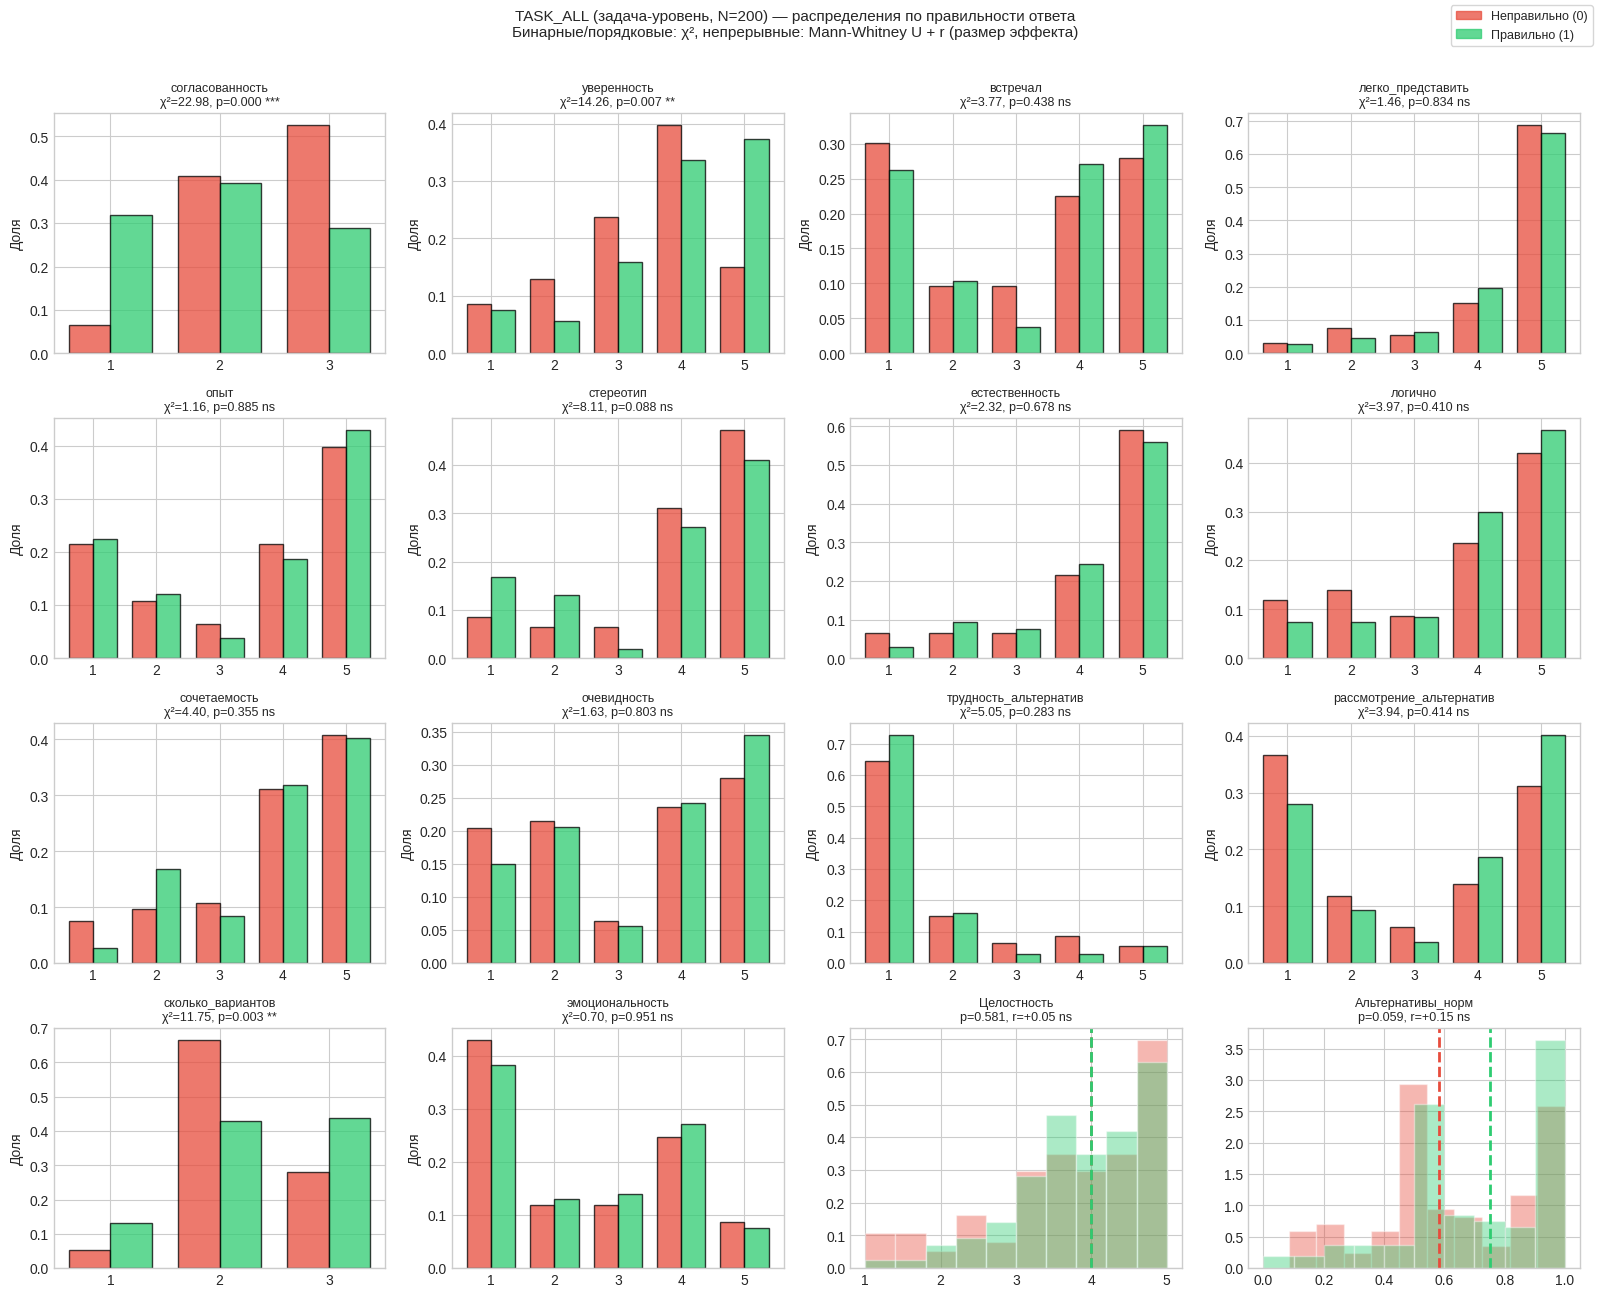


TASK_ALL (задача-уровень, N=200): статистика по всем признакам
Признак                                  Тип            статистика        p    r / φ
--------------------------------------------------------------------------------
согласованность                          ordinal      chi2=   22.98    0.0000  V= 0.339  ✅
уверенность                              ordinal      chi2=   14.26    0.0065  V= 0.267  ✅
встречал                                 ordinal      chi2=    3.77    0.4381  V= 0.137  ❌
легко_представить                        ordinal      chi2=    1.46    0.8343  V= 0.085  ❌
опыт                                     ordinal      chi2=    1.16    0.8852  V= 0.076  ❌
стереотип                                ordinal      chi2=    8.11    0.0878  V= 0.201  ❌
естественность                           ordinal      chi2=    2.32    0.6777  V= 0.108  ❌
логично                                  ordinal      chi2=    3.97    0.4096  V= 0.141  ❌
сочетаемость                             o

In [142]:
# TASK_ALL: 16 признаков задачного уровня
# Уровень анализа: каждая строка = одна задача одного участника (N=200)

plot_feature_group(df, TASK_ALL, TARGET,
                   group_name='TASK_ALL (задача-уровень, N=200)',
                   ncols=4)

Медиана правильных ответов: 2.5
Успешных: 20, менее успешных: 20


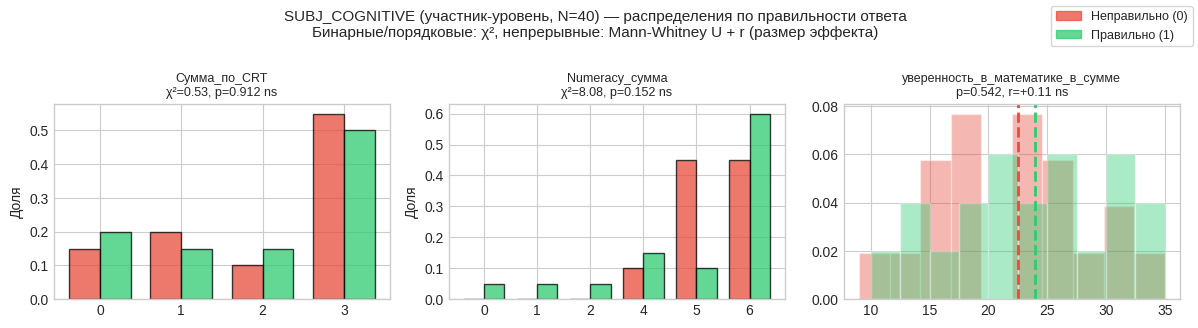


SUBJ_COGNITIVE (участник-уровень, N=40): статистика по всем признакам
Признак                                  Тип            статистика        p    r / φ
--------------------------------------------------------------------------------
Сумма_по_CRT                             ordinal      chi2=    0.53    0.9115  V= 0.115  ❌
Numeracy_сумма                           ordinal      chi2=    8.08    0.1517  V= 0.450  ❌
уверенность_в_математике_в_сумме         continuous    U=   177.0    0.5422  r=+0.115  ❌


In [143]:
# Участник-уровень: бинаризуем успешность по медиане
# (если ≥ медианы — «успешный», иначе — «менее успешный»)
med_success = df_subj['Количество_правильных_ответов'].median()
df_subj['успешный'] = (df_subj['Количество_правильных_ответов'] >= med_success).astype(int)

print(f'Медиана правильных ответов: {med_success}')
print(f'Успешных: {df_subj["успешный"].sum()}, менее успешных: {(df_subj["успешный"]==0).sum()}')

plot_feature_group(df_subj, SUBJ_COGNITIVE, 'успешный',
                   group_name='SUBJ_COGNITIVE (участник-уровень, N=40)',
                   ncols=3)

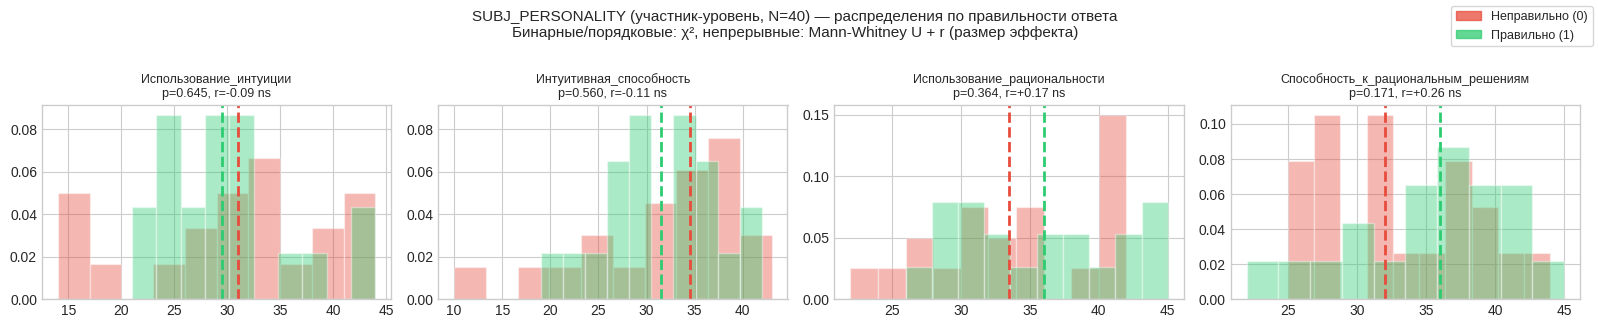


SUBJ_PERSONALITY (участник-уровень, N=40): статистика по всем признакам
Признак                                  Тип            статистика        p    r / φ
--------------------------------------------------------------------------------
Использование_интуиции                   continuous    U=   217.5    0.6450  r=-0.087  ❌
Интуитивная_способность                  continuous    U=   222.0    0.5601  r=-0.110  ❌
Использование_рациональности             continuous    U=   166.0    0.3640  r=+0.170  ❌
Способность_к_рациональным_решениям      continuous    U=   149.0    0.1711  r=+0.255  ❌


In [144]:
plot_feature_group(df_subj, SUBJ_PERSONALITY, 'успешный',
                   group_name='SUBJ_PERSONALITY (участник-уровень, N=40)',
                   ncols=4)

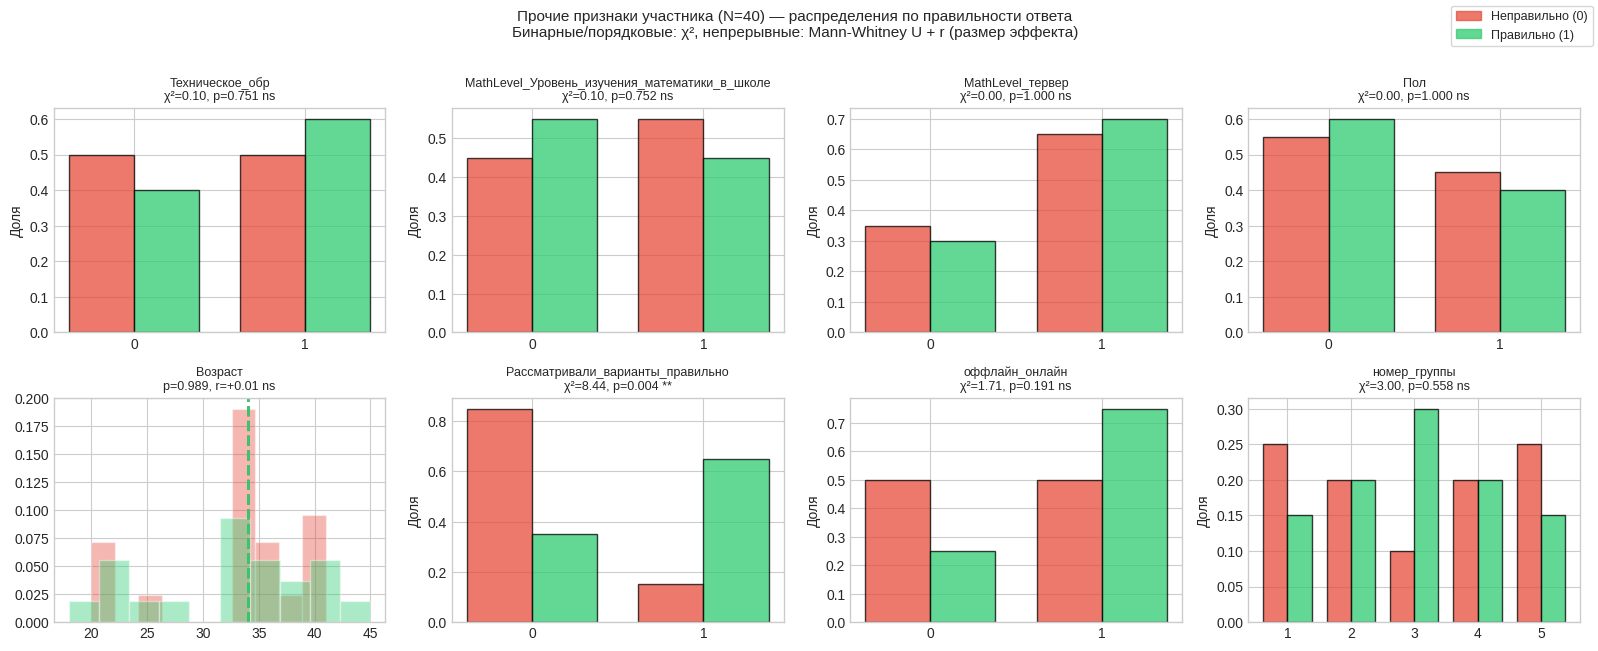


Прочие признаки участника (N=40): статистика по всем признакам
Признак                                  Тип            статистика        p    r / φ
--------------------------------------------------------------------------------
Техническое_обр                          binary       chi2=    0.10    0.7506  V= 0.050  ❌
MathLevel_Уровень_изучения_математики_в_школе binary       chi2=    0.10    0.7518  V= 0.050  ❌
MathLevel_тервер                         binary       chi2=    0.00    1.0000  V= 0.000  ❌
Пол                                      binary       chi2=    0.00    1.0000  V= 0.000  ❌
Возраст                                  continuous    U=   199.0    0.9891  r=+0.005  ❌
Рассматривали_варианты_правильно         binary       chi2=    8.44    0.0037  V= 0.459  ✅
оффлайн_онлайн                           binary       chi2=    1.71    0.1914  V= 0.207  ❌
номер_группы                             ordinal      chi2=    3.00    0.5578  V= 0.274  ❌


In [145]:
other_subj = SUBJ_EDU + SUBJ_INDIVIDUAL + SUBJ_REASONING + SUBJ_ENV

plot_feature_group(df_subj, other_subj, 'успешный',
                   group_name='Прочие признаки участника (N=40)',
                   ncols=4)

Смотрим на форму распределения — нормальность, скошенность, выбросы.

In [146]:
# Все количественные признаки из задачного уровня
from scipy.stats import skew, kurtosis

quant_feats = [f for f in TASK_ALL
               if classify_feature(df[f]) == 'continuous']

print(f'Количественных задача-признаков: {len(quant_feats)}')
print(f'{"Признак":<35} {"Mean":>7} {"SD":>6} {"Skew":>7} {"Kurt":>7} {"Shapiro-p":>10}')
print('-'*75)
for feat in quant_feats:
    s = df[feat].dropna()
    sw_p = shapiro(s)[1] if len(s) <= 5000 else float('nan')
    print(f'{feat:<35} {s.mean():>7.2f} {s.std():>6.2f} '
          f'{skew(s):>7.3f} {kurtosis(s):>7.3f} {sw_p:>10.4f}  '
          f'{"норм" if sw_p>.05 else "не норм"}')

# То же для участник-уровня
print('\nКоличественные признаки участника:')
print(f'{"Признак":<40} {"Mean":>7} {"SD":>6} {"Skew":>7} {"Shapiro-p":>10}')
print('-'*75)
quant_subj = [f for f in SUBJ_ALL
              if f in df_subj.columns and classify_feature(df_subj[f])=='continuous']
for feat in quant_subj:
    s = df_subj[feat].dropna()
    sw_p = shapiro(s)[1]
    print(f'{feat:<40} {s.mean():>7.2f} {s.std():>6.2f} '
          f'{skew(s):>7.3f} {sw_p:>10.4f}  '
          f'{"норм" if sw_p>.05 else "не норм"}')

Количественных задача-признаков: 2
Признак                                Mean     SD    Skew    Kurt  Shapiro-p
---------------------------------------------------------------------------
Целостность                            3.82   1.00  -0.795   0.084     0.0000  не норм
Альтернативы_норм                      0.67   0.26  -0.251  -0.918     0.0000  не норм

Количественные признаки участника:
Признак                                     Mean     SD    Skew  Shapiro-p
---------------------------------------------------------------------------
уверенность_в_математике_в_сумме           22.62   6.81  -0.052     0.6892  норм
Использование_интуиции                     29.95   7.62  -0.049     0.4234  норм
Интуитивная_способность                    31.75   7.08  -0.848     0.0714  норм
Использование_рациональности               34.73   6.21  -0.035     0.1990  норм
Способность_к_рациональным_решениям        34.15   5.93  -0.175     0.2402  норм
Возраст                                    32

2.1а Корреляции внутри TASK_ALL (N=200)


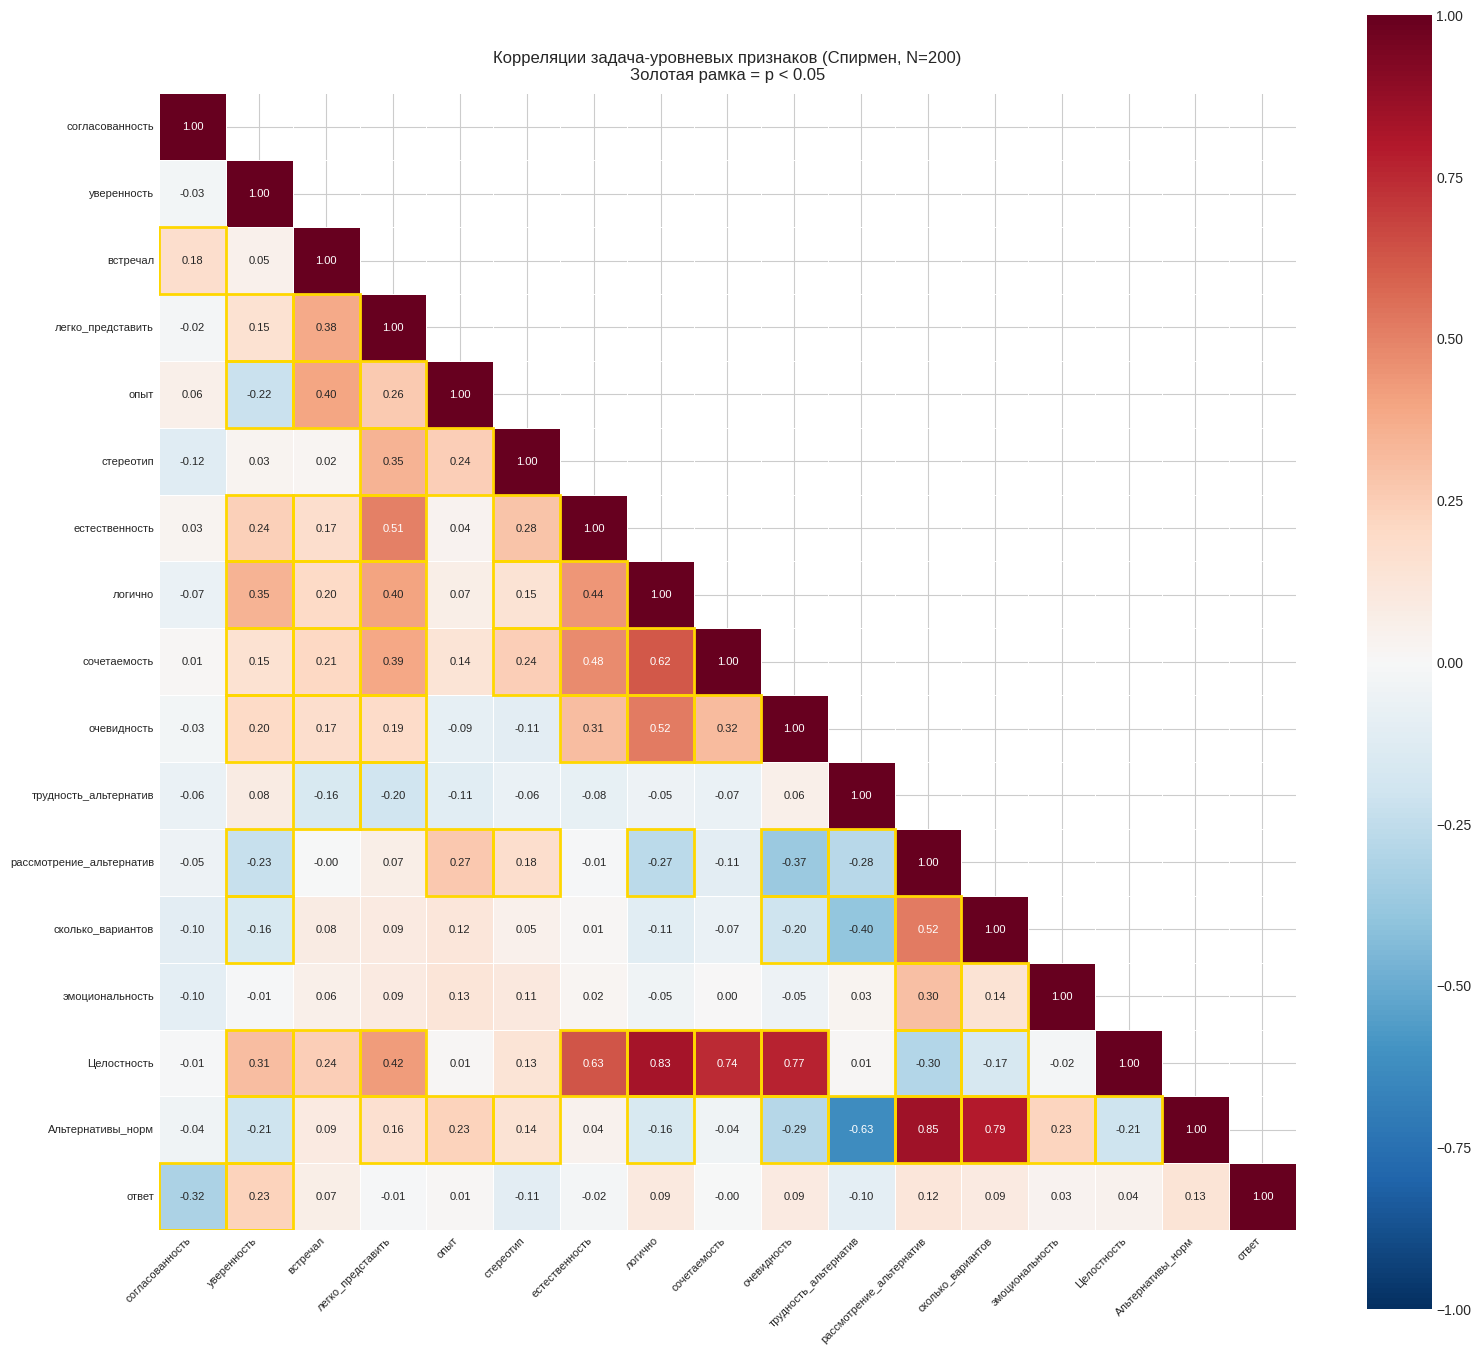

In [147]:
# ── Функция: матрица корреляций Спирмена ──────────────────────────────────
def spearman_matrix(data, cols):
    n = len(cols)
    R = np.zeros((n, n))
    P = np.ones((n, n))
    for i, c1 in enumerate(cols):
        for j, c2 in enumerate(cols):
            if i == j:
                R[i,j] = 1.0
            else:
                r, p = spearmanr(data[c1], data[c2], nan_policy='omit')
                R[i,j] = r; P[i,j] = p
    return (pd.DataFrame(R, index=cols, columns=cols),
            pd.DataFrame(P, index=cols, columns=cols))

def plot_corr_heatmap(corr_df, pval_df, title, figsize=(13, 11)):
    fig, ax = plt.subplots(figsize=figsize)
    mask = np.triu(np.ones_like(corr_df, dtype=bool), k=1)
    sns.heatmap(corr_df, mask=mask,
                annot=True, fmt='.2f', cmap='RdBu_r', center=0,
                vmin=-1, vmax=1, square=True, linewidths=.4,
                annot_kws={'size': 8}, ax=ax)
    # Золотая рамка — значимые ячейки
    n = len(corr_df)
    for i in range(n):
        for j in range(i):
            if pval_df.iloc[i, j] < 0.05:
                ax.add_patch(patches.Rectangle(
                    (j, i), 1, 1, fill=False, edgecolor='gold', lw=2))
    ax.set_title(title + '\nЗолотая рамка = p < 0.05', fontsize=12, pad=10)
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.yticks(fontsize=8)
    plt.tight_layout()
    plt.show()

# ── 2.1а TASK_ALL: корреляции задача-уровневых признаков ──────────────────────
print('2.1а Корреляции внутри TASK_ALL (N=200)')
corr_t, pval_t = spearman_matrix(df, TASK_ALL + [TARGET])
plot_corr_heatmap(corr_t, pval_t,
                  title='Корреляции задача-уровневых признаков (Спирмен, N=200)',
                  figsize=(16, 14))

2.1б Корреляции внутри SUBJ_ALL + успешность (N=40)


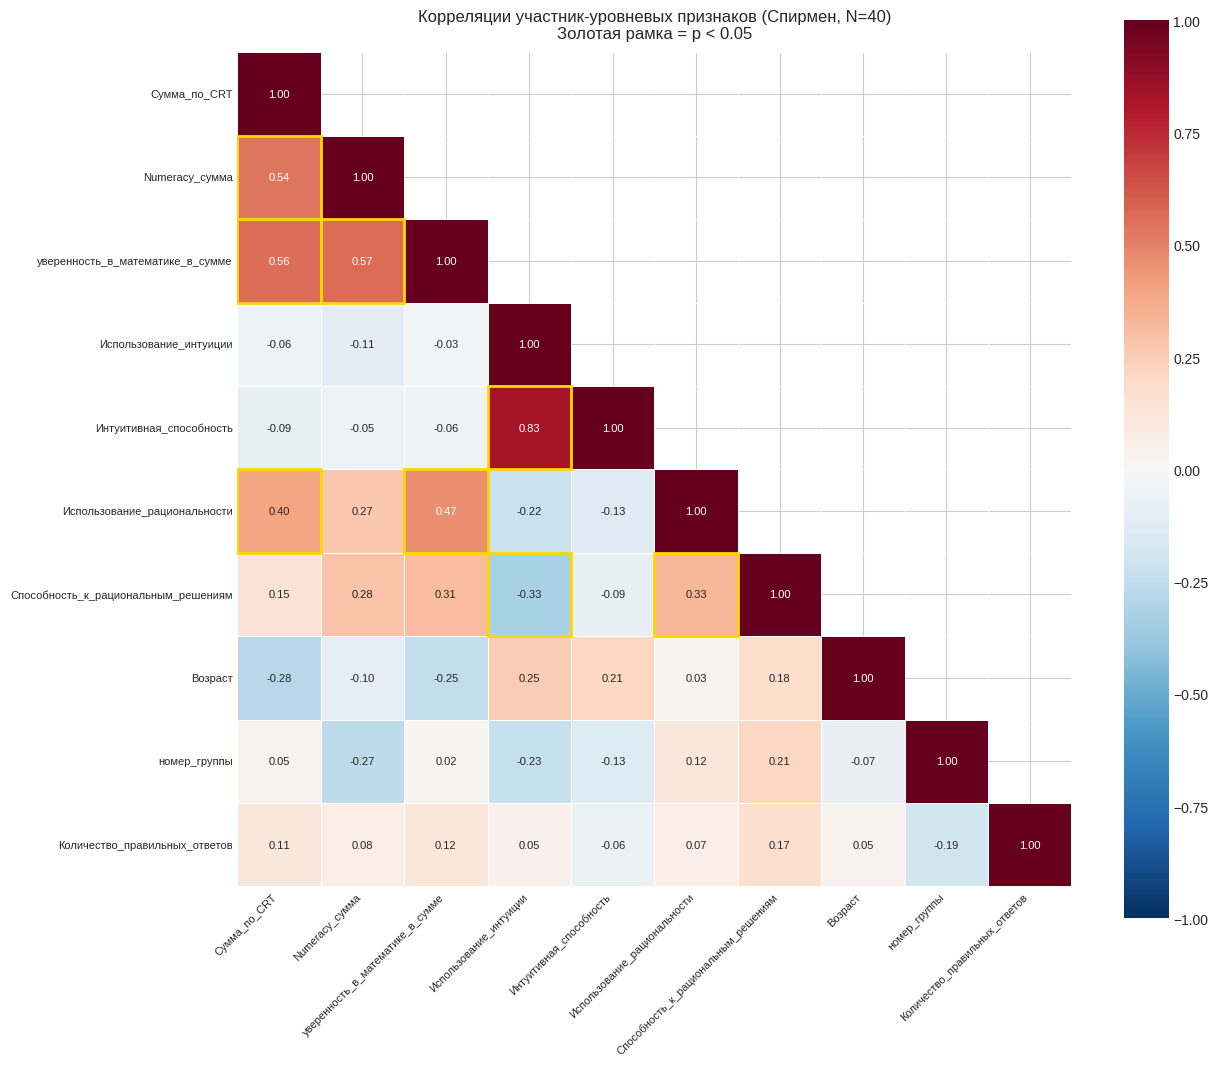

In [148]:
# ── 2.1б SUBJ_ALL: корреляции участник-уровневых признаков ──────────────────
print('2.1б Корреляции внутри SUBJ_ALL + успешность (N=40)')

subj_quant = [f for f in SUBJ_ALL
              if f in df_subj.columns
              and df_subj[f].nunique() > 2]  # исключаем бинарные

corr_s, pval_s = spearman_matrix(df_subj,
                                  subj_quant + ['Количество_правильных_ответов'])
plot_corr_heatmap(corr_s, pval_s,
                  title='Корреляции участник-уровневых признаков (Спирмен, N=40)',
                  figsize=(13, 11))

2.1а Корреляции внутри TASK_ALL + SUBJ_ALL (N=200)


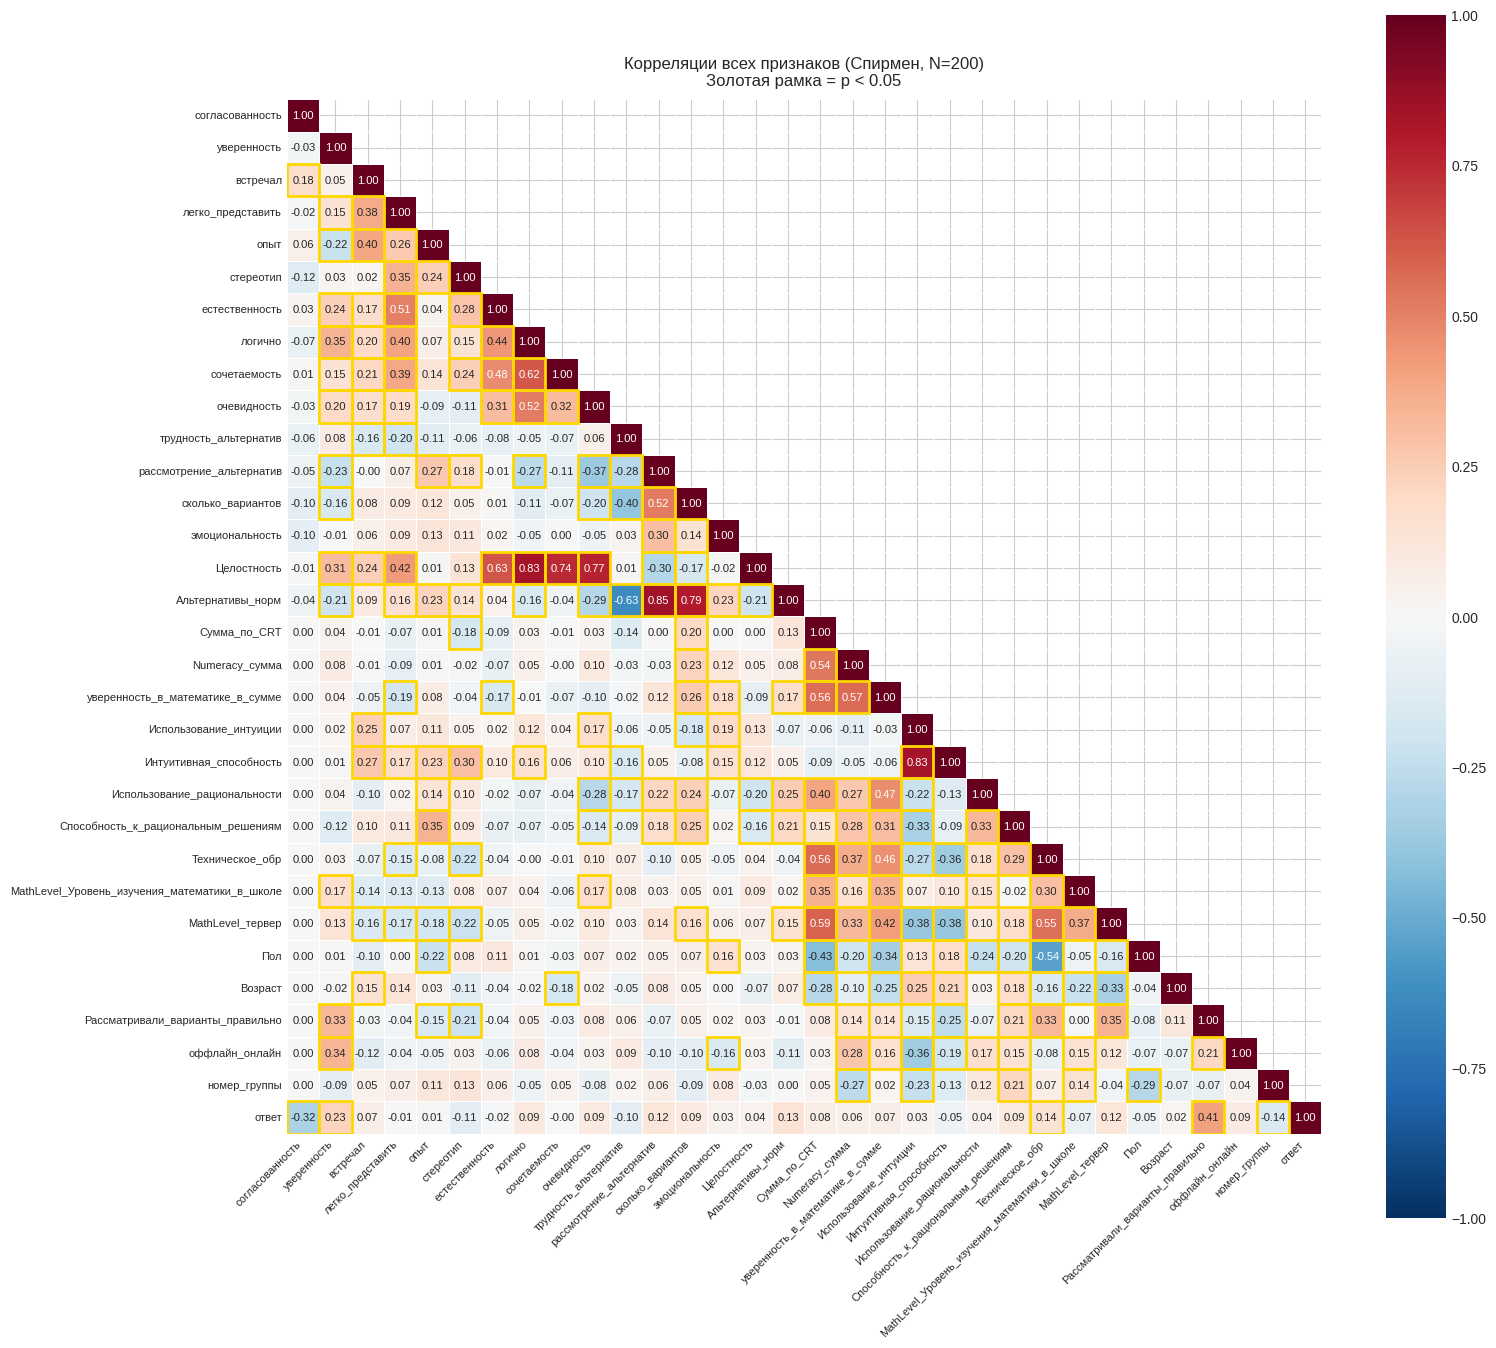

In [149]:
# TASK_ALL + SUBJ_ALL: корреляции всех  признаков ──────────────────────
print('2.1а Корреляции внутри TASK_ALL + SUBJ_ALL (N=200)')
corr_t, pval_t = spearman_matrix(df, TASK_ALL + SUBJ_ALL+ [TARGET])
plot_corr_heatmap(corr_t, pval_t,
                  title='Корреляции всех признаков (Спирмен, N=200)',
                  figsize=(16, 14))

In [150]:
# ── 2.1в Таблица значимых попарных корреляций ────────────────────────────────
print('\nЗначимые попарные корреляции (p < 0.05) — задача-уровень:')
print(f'{"Признак 1":<32} {"Признак 2":<32} {"ρ":>7} {"p":>8}')
print('-'*82)

all_task = TASK_ALL + [TARGET]
for i, c1 in enumerate(all_task):
    for j, c2 in enumerate(all_task):
        if j <= i: continue
        if c1 not in df.columns or c2 not in df.columns: continue
        r, p = spearmanr(df[c1], df[c2], nan_policy='omit')
        if p < 0.05:
            mark = ' ← с таргетом' if TARGET in (c1, c2) else ''
            print(f'{c1:<32} {c2:<32} {r:>+7.3f} {p:>8.4f}{mark}')


Значимые попарные корреляции (p < 0.05) — задача-уровень:
Признак 1                        Признак 2                              ρ        p
----------------------------------------------------------------------------------
согласованность                  встречал                          +0.176   0.0128
согласованность                  ответ                             -0.318   0.0000 ← с таргетом
уверенность                      легко_представить                 +0.154   0.0289
уверенность                      опыт                              -0.221   0.0016
уверенность                      естественность                    +0.239   0.0006
уверенность                      логично                           +0.348   0.0000
уверенность                      сочетаемость                      +0.153   0.0301
уверенность                      очевидность                       +0.203   0.0039
уверенность                      рассмотрение_альтернатив          -0.228   0.0012
уверенность    

In [184]:
# ── 2.1в Таблица значимых попарных корреляций ────────────────────────────────
print('\nЗначимые попарные корреляции (p < 0.05) — задача-уровень:')
print(f'{"Признак 1":<32} {"Признак 2":<32} {"ρ":>7} {"p":>8}')
print('-'*82)

all_subj = SUBJ_ALL + ['Количество_правильных_ответов']
for i, c1 in enumerate(all_subj):
    for j, c2 in enumerate(all_subj):
        if j <= i: continue
        if c1 not in df_subj.columns or c2 not in df_subj.columns: continue
        r, p = spearmanr(df_subj[c1], df_subj[c2], nan_policy='omit')
        if p < 0.05:
            mark = ' ← с таргетом' if 'Количество_правильных_ответов' in (c1, c2) else ''
            print(f'{c1:<32} {c2:<32} {r:>+7.3f} {p:>8.4f}{mark}')


Значимые попарные корреляции (p < 0.05) — задача-уровень:
Признак 1                        Признак 2                              ρ        p
----------------------------------------------------------------------------------
Сумма_по_CRT                     Numeracy_сумма                    +0.538   0.0003
Сумма_по_CRT                     уверенность_в_математике_в_сумме  +0.559   0.0002
Сумма_по_CRT                     Использование_рациональности      +0.396   0.0113
Сумма_по_CRT                     Техническое_обр                   +0.564   0.0001
Сумма_по_CRT                     MathLevel_Уровень_изучения_математики_в_школе  +0.354   0.0251
Сумма_по_CRT                     MathLevel_тервер                  +0.587   0.0001
Сумма_по_CRT                     Пол                               -0.427   0.0060
Numeracy_сумма                   уверенность_в_математике_в_сумме  +0.565   0.0001
Numeracy_сумма                   Техническое_обр                   +0.367   0.0197
Numeracy_сумма 

Дисперсионный анализ: как согласованность влияет на признаки
согласованность — это управляемая переменная эксперимента (1 / 2 / 3 уровень).
Вопрос: отличаются ли субъективные оценки ситуаций с разной согласованностью?

Если да — манипуляция работает, признаки несут разную информацию при разных уровнях.
Если нет — субъективные оценки не зависят от согласованности, это важный результат.

Используем Kruskal-Wallis (непараметрический аналог ANOVA) — т.к. большинство шкал ненормальные.

In [153]:
# ── Kruskal-Wallis: согласованность → каждый задача-признак ─────────────────

sog_lvls = sorted(df['согласованность'].unique())
labels_sog = {1: 'Низкая', 2: 'Средняя', 3: 'Высокая'}
colors_sog = {1: '#e74c3c', 2: '#f39c12', 3: '#2ecc71'}

# Признаки для ANOVA (все задача-уровневые кроме самой согласованности)
anova_feats = [f for f in TASK_ALL if f != 'согласованность' and f in df.columns]

print('Kruskal-Wallis: согласованность (1/2/3) → признаки задачи')
print(f'{"Признак":<35} {"H":>7} {"p":>9}  Медианы по уровням')
print('-'*85)

anova_results = []
for feat in anova_feats:
    grps = [df[df['согласованность'] == lvl][feat].dropna() for lvl in sog_lvls]
    H, p = kruskal(*grps)
    meds = [f'{g.median():.2f}' for g in grps]
    sig = '✅' if p < 0.05 else '❌'
    print(f'{feat:<35} {H:>7.3f} {p:>9.4f}  '
          f'[1:{meds[0]}  2:{meds[1]}  3:{meds[2]}]  {sig}')
    anova_results.append({'feat': feat, 'H': H, 'p': p, 'sig': p < 0.05})

anova_df = pd.DataFrame(anova_results).sort_values('p')
print(f'\nЗначимых: {anova_df["sig"].sum()} из {len(anova_df)}')

Kruskal-Wallis: согласованность (1/2/3) → признаки задачи
Признак                                   H         p  Медианы по уровням
-------------------------------------------------------------------------------------
уверенность                           0.228    0.8921  [1:4.00  2:4.00  3:4.00]  ❌
встречал                              6.590    0.0371  [1:2.50  2:3.50  3:4.00]  ✅
легко_представить                     0.083    0.9593  [1:5.00  2:5.00  3:5.00]  ❌
опыт                                  0.927    0.6291  [1:4.00  2:4.00  3:4.00]  ❌
стереотип                             3.178    0.2041  [1:4.50  2:4.00  3:4.00]  ❌
естественность                        0.918    0.6318  [1:5.00  2:5.00  3:5.00]  ❌
логично                               1.746    0.4178  [1:5.00  2:4.00  3:4.00]  ❌
сочетаемость                          0.308    0.8571  [1:4.00  2:4.00  3:4.00]  ❌
очевидность                           0.323    0.8510  [1:4.00  2:4.00  3:4.00]  ❌
трудность_альтернатив              

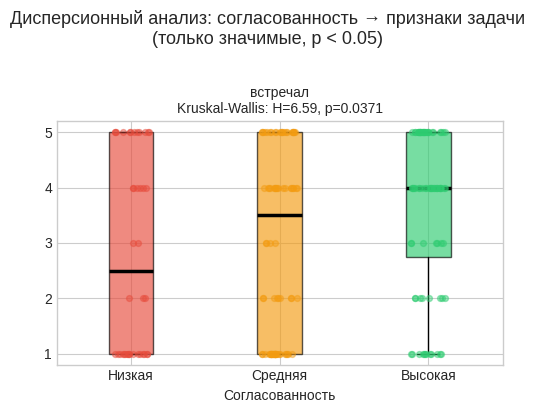

In [154]:
# ── Визуализация: boxplot для значимых признаков ─────────────────────────────

sig_feats = anova_df[anova_df['sig']]['feat'].tolist()

if not sig_feats:
    print('Значимых признаков нет — строим топ-6 по H')
    sig_feats = anova_df.head(6)['feat'].tolist()

ncols = min(3, len(sig_feats))
nrows = (len(sig_feats) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4))
axes = np.array(axes).flatten()

for idx, feat in enumerate(sig_feats):
    ax = axes[idx]
    grp_data  = [df[df['согласованность'] == lvl][feat].dropna() for lvl in sog_lvls]
    H, p = kruskal(*grp_data)

    bp = ax.boxplot(grp_data,
                    labels=[labels_sog[l] for l in sog_lvls],
                    patch_artist=True,
                    medianprops=dict(color='black', lw=2.5))
    for patch, lvl in zip(bp['boxes'], sog_lvls):
        patch.set_facecolor(colors_sog[lvl]); patch.set_alpha(0.65)

    # Индивидуальные точки (jitter)
    for i, (grp, lvl) in enumerate(zip(grp_data, sog_lvls)):
        jit = np.random.uniform(-0.12, 0.12, len(grp))
        ax.scatter(np.full(len(grp), i+1) + jit, grp,
                   color=colors_sog[lvl], alpha=0.45, s=18, zorder=3)

    ax.set_title(f'{feat}\nKruskal-Wallis: H={H:.2f}, p={p:.4f}', fontsize=10)
    ax.set_xlabel('Согласованность')

for idx in range(len(sig_feats), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Дисперсионный анализ: согласованность → признаки задачи\n'
             '(только значимые, p < 0.05)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [155]:
# ── Пост-хок: попарные сравнения для значимых признаков ─────────────────────
# Mann-Whitney с поправкой Бонферрони (α = 0.05 / 3 пар = 0.017)

ALPHA_BONF = 0.05 / 3

print('Пост-хок сравнения (Mann-Whitney, поправка Бонферрони α=0.017):')
print()

for feat in sig_feats:
    H, p = kruskal(*[df[df['согласованность']==lvl][feat].dropna() for lvl in sog_lvls])
    print(f'{feat}  (H={H:.2f}, p={p:.4f}):')
    for l1, l2 in combinations(sog_lvls, 2):
        g1 = df[df['согласованность']==l1][feat].dropna()
        g2 = df[df['согласованность']==l2][feat].dropna()
        u, p_pair = mannwhitneyu(g1, g2, alternative='two-sided')
        r_rb = 1 - 2*u/(len(g1)*len(g2))
        sig = '✅' if p_pair < ALPHA_BONF else '❌'
        print(f'  {labels_sog[l1]} vs {labels_sog[l2]}: '
              f'U={u:.0f}, p={p_pair:.4f}, r={r_rb:+.3f}  {sig}')
    print()

Пост-хок сравнения (Mann-Whitney, поправка Бонферрони α=0.017):

встречал  (H=6.59, p=0.0371):
  Низкая vs Средняя: U=1522, p=0.6527, r=+0.049  ❌
  Низкая vs Высокая: U=1235, p=0.0355, r=+0.228  ❌
  Средняя vs Высокая: U=2583, p=0.0295, r=+0.193  ❌



In [156]:
# Признаки для PCA 1: TASK_ALL без интегральных
PCA_TASK = [f for f in TASK_ALL if f not in TASK_INTEGRAL]
print(f'PCA 1 — задача-признаки: {len(PCA_TASK)} шт.')
print(PCA_TASK)

# Признаки для PCA 2: количественные из SUBJ_ALL (исключаем бинарные)
PCA_SUBJ = [f for f in SUBJ_ALL
            if f in df_subj.columns and df_subj[f].nunique() > 2]
print(f'\nPCA 2 — участник-признаки: {len(PCA_SUBJ)} шт.')
print(PCA_SUBJ)

PCA 1 — задача-признаки: 14 шт.
['согласованность', 'уверенность', 'встречал', 'легко_представить', 'опыт', 'стереотип', 'естественность', 'логично', 'сочетаемость', 'очевидность', 'трудность_альтернатив', 'рассмотрение_альтернатив', 'сколько_вариантов', 'эмоциональность']

PCA 2 — участник-признаки: 9 шт.
['Сумма_по_CRT', 'Numeracy_сумма', 'уверенность_в_математике_в_сумме', 'Использование_интуиции', 'Интуитивная_способность', 'Использование_рациональности', 'Способность_к_рациональным_решениям', 'Возраст', 'номер_группы']


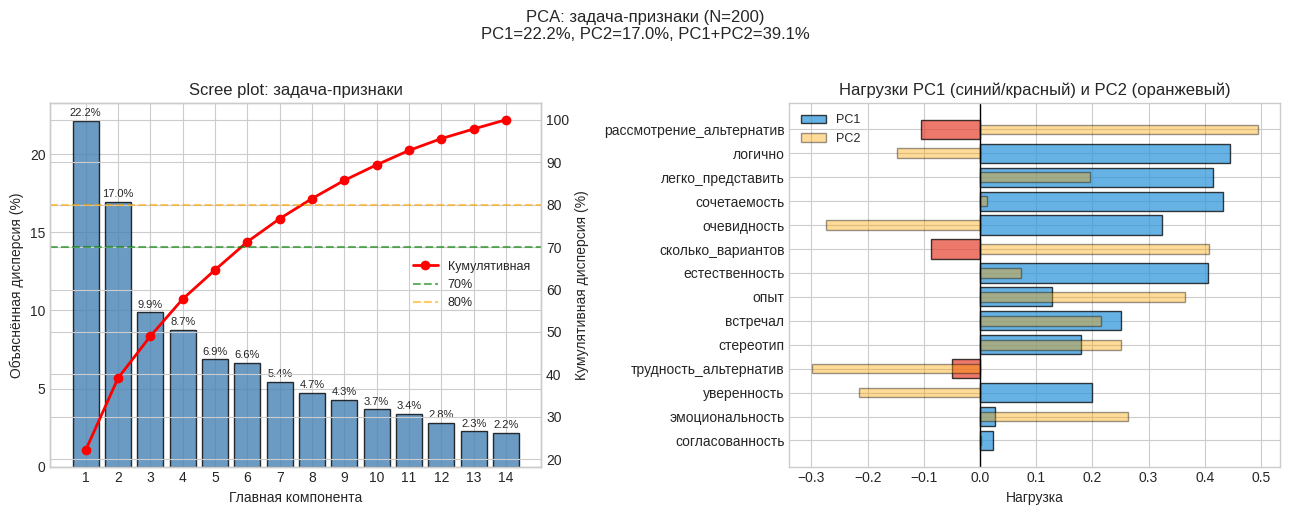


Объяснённая дисперсия по компонентам:
  PC1: 22.2%  (кум. 22.2%)
  PC2: 17.0%  (кум. 39.1%)
  PC3: 9.9%  (кум. 49.0%)
  PC4: 8.7%  (кум. 57.8%)
  PC5: 6.9%  (кум. 64.6%)
  PC6: 6.6%  (кум. 71.2%)
  PC7: 5.4%  (кум. 76.7%)
  PC8: 4.7%  (кум. 81.4%)
  PC9: 4.3%  (кум. 85.7%)
  PC10: 3.7%  (кум. 89.4%)
  PC11: 3.4%  (кум. 92.8%)
  PC12: 2.8%  (кум. 95.6%)
  PC13: 2.3%  (кум. 97.8%)
  PC14: 2.2%  (кум. 100.0%)


In [157]:
# ── Подготовка данных ──────────────────────────────────────────────────────
X_task = df[PCA_TASK].dropna()
idx_valid = X_task.index

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_task)

# ── PCA ────────────────────────────────────────────────────────────────────
pca = PCA(n_components=len(PCA_TASK))
scores = pca.fit_transform(X_scaled)
ev = pca.explained_variance_ratio_

# ── Scree plot ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Левый: столбцы + линия кумулятивной дисперсии
bars = axes[0].bar(range(1, len(ev)+1), ev*100,
                   color='steelblue', edgecolor='black', alpha=0.8)
ax2 = axes[0].twinx()
ax2.plot(range(1, len(ev)+1), np.cumsum(ev)*100,
         'ro-', lw=2, ms=6, label='Кумулятивная')
ax2.axhline(70, color='green', ls='--', alpha=0.6, label='70%')
ax2.axhline(80, color='orange', ls='--', alpha=0.6, label='80%')
ax2.set_ylabel('Кумулятивная дисперсия (%)')
ax2.legend(fontsize=9, loc='center right')
axes[0].set_xlabel('Главная компонента')
axes[0].set_ylabel('Объяснённая дисперсия (%)')
axes[0].set_title('Scree plot: задача-признаки')
axes[0].set_xticks(range(1, len(ev)+1))
for i, (bar, v) in enumerate(zip(bars, ev)):
    axes[0].text(bar.get_x()+bar.get_width()/2, v*100+0.3,
                 f'{v*100:.1f}%', ha='center', fontsize=8)

# Правый: таблица нагрузок PC1 и PC2
load_df = pd.DataFrame(pca.components_[:2].T,
                        index=PCA_TASK, columns=['PC1','PC2'])
load_df['|вектор|'] = np.sqrt(load_df['PC1']**2 + load_df['PC2']**2)
load_sorted = load_df.sort_values('|вектор|', ascending=True)

colors_bar = ['#e74c3c' if v < 0 else '#3498db'
              for v in load_sorted['PC1']]
axes[1].barh(load_sorted.index, load_sorted['PC1'],
             color=colors_bar, edgecolor='black', alpha=0.75, label='PC1')
axes[1].barh(load_sorted.index, load_sorted['PC2'],
             color='orange', edgecolor='black', alpha=0.4,
             label='PC2', height=0.4)
axes[1].axvline(0, color='black', lw=1)
axes[1].set_xlabel('Нагрузка')
axes[1].set_title('Нагрузки PC1 (синий/красный) и PC2 (оранжевый)')
axes[1].legend(fontsize=9)

plt.suptitle(f'PCA: задача-признаки (N=200)\n'
             f'PC1={ev[0]:.1%}, PC2={ev[1]:.1%}, '
             f'PC1+PC2={ev[0]+ev[1]:.1%}',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

print('\nОбъяснённая дисперсия по компонентам:')
for i, (e, c) in enumerate(zip(ev, np.cumsum(ev)), 1):
    print(f'  PC{i}: {e:.1%}  (кум. {c:.1%})')

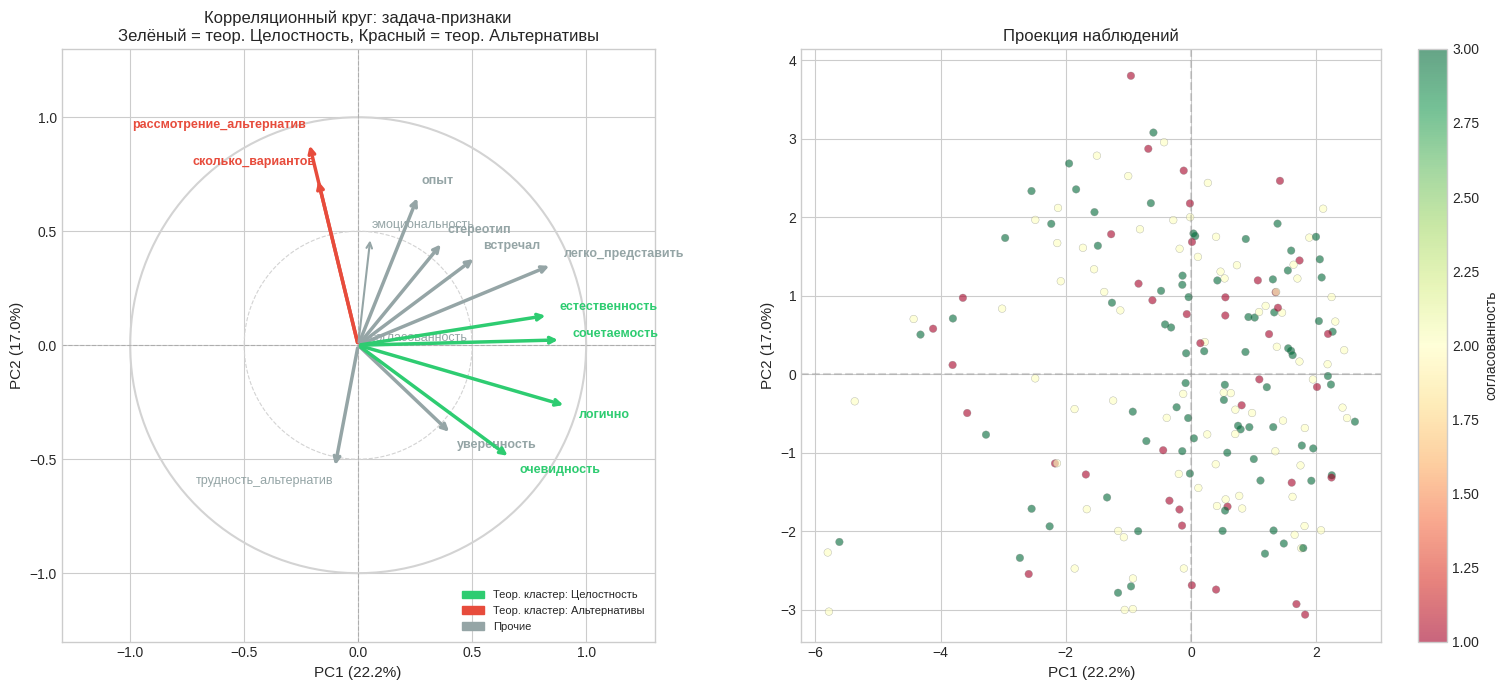

In [158]:
# ── Корреляционный круг ────────────────────────────────────────────────────
# Нагрузки в корреляционном круге = корреляция переменной с компонентой
# = component_loading × sqrt(eigenvalue) / sqrt(n_features)
# Стандартный способ: loading × sqrt(eigenvalue)

def correlation_circle(pca_model, feature_names, scores, pc_x=0, pc_y=1,
                        color_by=None, cmap_vals=None, color_label='',
                        title='Корреляционный круг'):

    ev    = pca_model.explained_variance_
    ev_r  = pca_model.explained_variance_ratio_

    # Нагрузки (корреляции переменной с осями)
    load  = pca_model.components_[[pc_x, pc_y], :].T      # (n_feat, 2)
    coord = load * np.sqrt(ev[[pc_x, pc_y]])               # масштаб к кругу

    # Нормируем так, чтобы самый длинный вектор = 0.95
    max_len = np.sqrt((coord**2).sum(axis=1)).max()
    coord   = coord / max_len * 0.95

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # ── Левый: корреляционный круг ──────────────────────────────────────
    ax = axes[0]
    theta = np.linspace(0, 2*np.pi, 300)
    ax.plot(np.cos(theta), np.sin(theta), color='lightgray', lw=1.5)
    ax.plot(np.cos(theta)*.5, np.sin(theta)*.5,
            color='lightgray', lw=0.8, ls='--')

    # Цветовые группы переменных
    group_colors = {
        'целостность': ('#2ecc71', ['естественность','логично','сочетаемость','очевидность']),
        'альтернативы': ('#e74c3c', ['трудность_альтернатив_инв','рассмотрение_альтернатив','сколько_вариантов']),
        'прочие': ('#95a5a6', None)
    }
    feat_color = {}
    for gname, (gcol, gfeats) in group_colors.items():
        if gfeats:
            for f in gfeats:
                feat_color[f] = gcol
    for f in feature_names:
        if f not in feat_color:
            feat_color[f] = '#95a5a6'

    for i, (name, (x, y)) in enumerate(zip(feature_names, coord)):
        col   = feat_color[name]
        length = np.sqrt(x**2 + y**2)
        lw    = 2.5 if length > 0.5 else 1.5
        ax.annotate('', xy=(x, y), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color=col, lw=lw))
        ha = 'left' if x >= 0 else 'right'
        va = 'bottom' if y >= 0 else 'top'
        offset = 1.06
        ax.text(x*offset, y*offset, name, ha=ha, va=va,
                fontsize=9, color=col,
                fontweight='bold' if length > 0.55 else 'normal')

    ax.axhline(0, color='gray', ls='--', alpha=0.4, lw=0.8)
    ax.axvline(0, color='gray', ls='--', alpha=0.4, lw=0.8)
    ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3)
    ax.set_aspect('equal')
    ax.set_xlabel(f'PC{pc_x+1} ({ev_r[pc_x]:.1%})', fontsize=11)
    ax.set_ylabel(f'PC{pc_y+1} ({ev_r[pc_y]:.1%})', fontsize=11)
    ax.set_title(title, fontsize=12)

    # Легенда групп
    legend_patches = [
        mpatches.Patch(color='#2ecc71', label='Теор. кластер: Целостность'),
        mpatches.Patch(color='#e74c3c', label='Теор. кластер: Альтернативы'),
        mpatches.Patch(color='#95a5a6', label='Прочие'),
    ]
    ax.legend(handles=legend_patches, fontsize=8, loc='lower right')

    # ── Правый: проекция наблюдений ────────────────────────────────────
    ax2 = axes[1]
    if color_by is not None:
        sc = ax2.scatter(scores[:, pc_x], scores[:, pc_y],
                         c=color_by, cmap=cmap_vals,
                         alpha=0.6, s=30, edgecolors='gray', lw=0.3)
        plt.colorbar(sc, ax=ax2, label=color_label)
    else:
        ax2.scatter(scores[:, pc_x], scores[:, pc_y],
                    alpha=0.5, s=30, color='steelblue')
    ax2.axhline(0, color='gray', ls='--', alpha=0.3)
    ax2.axvline(0, color='gray', ls='--', alpha=0.3)
    ax2.set_xlabel(f'PC{pc_x+1} ({ev_r[pc_x]:.1%})', fontsize=11)
    ax2.set_ylabel(f'PC{pc_y+1} ({ev_r[pc_y]:.1%})', fontsize=11)
    ax2.set_title('Проекция наблюдений', fontsize=12)

    plt.tight_layout()
    plt.show()

    return coord

# Цвет точек = согласованность задачи
sog = df.loc[idx_valid, 'согласованность'].values

coord_task = correlation_circle(
    pca, PCA_TASK, scores,
    color_by=sog, cmap_vals='RdYlGn', color_label='согласованность',
    title='Корреляционный круг: задача-признаки\nЗелёный = теор. Целостность, Красный = теор. Альтернативы'
)

 PCA на признаках участника (SUBJ_ALL)
Отдельный анализ на уровне участника (N=40).
Цвет точек = количество правильных ответов.

  PC1: 30.2%  (кум. 30.2%)
  PC2: 20.5%  (кум. 50.6%)
  PC3: 15.6%  (кум. 66.2%)
  PC4: 10.6%  (кум. 76.9%)
  PC5: 7.4%  (кум. 84.3%)
  PC6: 5.8%  (кум. 90.1%)
  PC7: 4.7%  (кум. 94.8%)
  PC8: 4.1%  (кум. 98.9%)
  PC9: 1.1%  (кум. 100.0%)


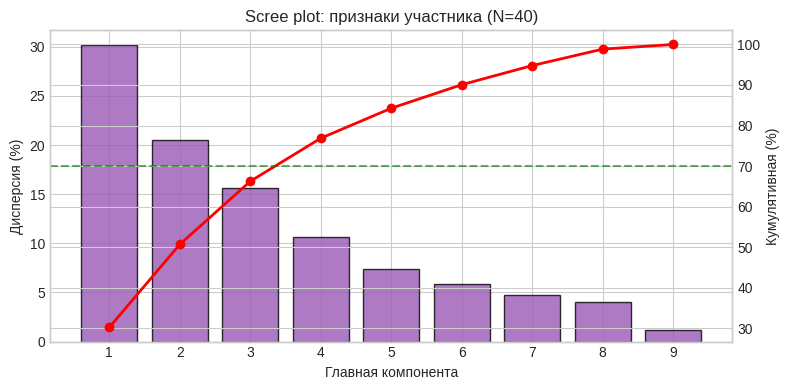

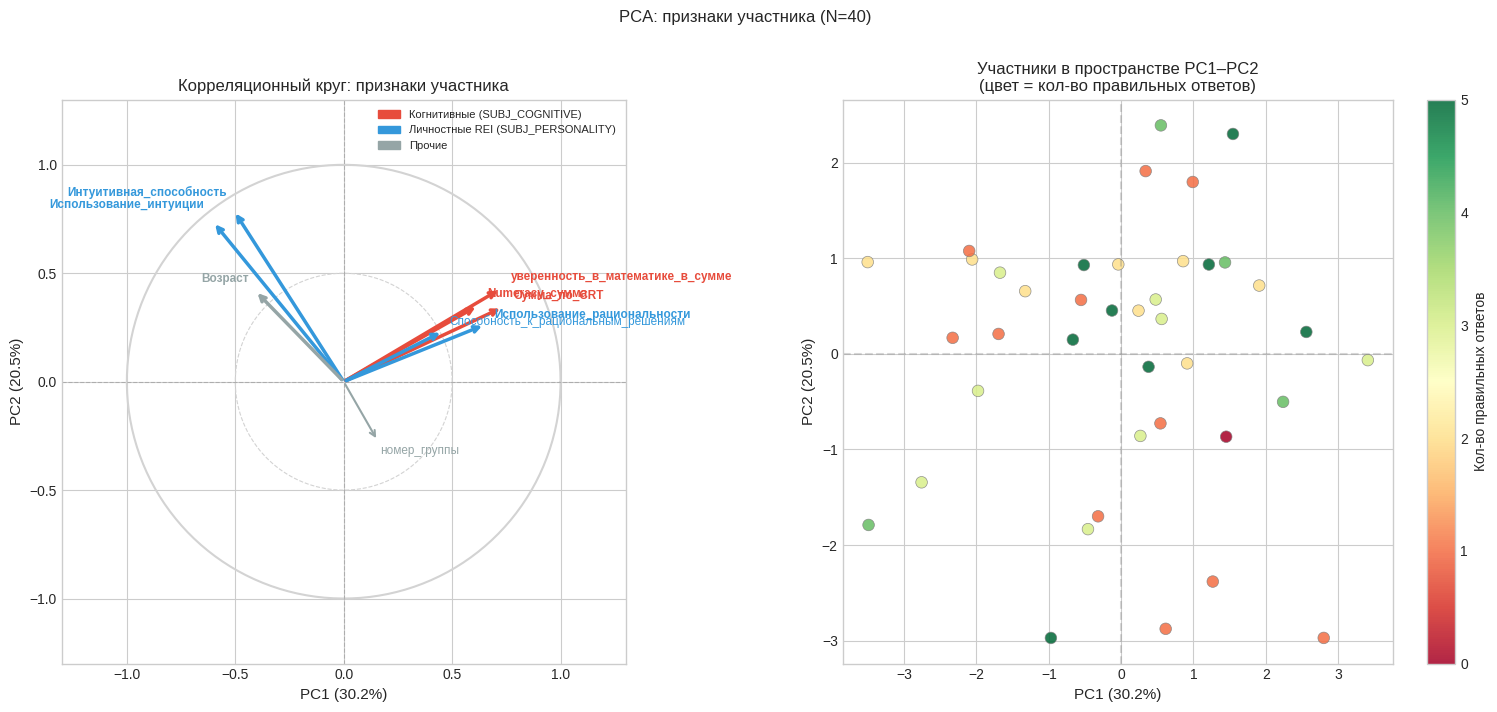


Корреляция PC с количеством правильных ответов:
  PC1: ρ=+0.041, p=0.8008  ❌
  PC2: ρ=+0.080, p=0.6225  ❌
  PC3: ρ=-0.040, p=0.8076  ❌
  PC4: ρ=-0.077, p=0.6363  ❌


In [159]:
X_subj = df_subj[PCA_SUBJ].dropna()
idx_subj = X_subj.index

scaler_s = StandardScaler()
X_subj_sc = scaler_s.fit_transform(X_subj)

pca_s = PCA(n_components=len(PCA_SUBJ))
scores_s = pca_s.fit_transform(X_subj_sc)
ev_s = pca_s.explained_variance_ratio_

# Scree
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(ev_s)+1), ev_s*100,
       color='#9b59b6', edgecolor='black', alpha=0.8)
ax2 = ax.twinx()
ax2.plot(range(1, len(ev_s)+1), np.cumsum(ev_s)*100, 'ro-', lw=2, ms=6)
ax2.axhline(70, color='green', ls='--', alpha=0.6)
ax.set_xlabel('Главная компонента')
ax.set_ylabel('Дисперсия (%)')
ax2.set_ylabel('Кумулятивная (%)')
ax.set_title(f'Scree plot: признаки участника (N=40)')
ax.set_xticks(range(1, len(ev_s)+1))
for i, (e, c) in enumerate(zip(ev_s, np.cumsum(ev_s)), 1):
    print(f'  PC{i}: {e:.1%}  (кум. {c:.1%})')
plt.tight_layout()
plt.show()

# Корреляционный круг для участника
success = df_subj.loc[idx_subj, 'Количество_правильных_ответов'].values

# Без группировки цветом — просто функция без color_by
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
pca_s2 = PCA(n_components=len(PCA_SUBJ))
pca_s2.fit(X_subj_sc)
ev_s2 = pca_s2.explained_variance_
ev_r2 = pca_s2.explained_variance_ratio_

load_s = pca_s2.components_[[0, 1], :].T
coord_s = load_s * np.sqrt(ev_s2[[0, 1]])
max_l = np.sqrt((coord_s**2).sum(axis=1)).max()
coord_s = coord_s / max_l * 0.95

ax = axes[0]
theta = np.linspace(0, 2*np.pi, 300)
ax.plot(np.cos(theta), np.sin(theta), color='lightgray', lw=1.5)
ax.plot(np.cos(theta)*.5, np.sin(theta)*.5,
        color='lightgray', lw=0.8, ls='--')

# Цветовые группы субъектных признаков
subj_group_color = {}
for f in SUBJ_COGNITIVE:
    subj_group_color[f] = '#e74c3c'
for f in SUBJ_PERSONALITY:
    subj_group_color[f] = '#3498db'
for f in PCA_SUBJ:
    if f not in subj_group_color:
        subj_group_color[f] = '#95a5a6'

for name, (x, y) in zip(PCA_SUBJ, coord_s):
    col = subj_group_color.get(name, '#95a5a6')
    length = np.sqrt(x**2 + y**2)
    ax.annotate('', xy=(x, y), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=col,
                                lw=2.5 if length > 0.5 else 1.5))
    ha = 'left' if x >= 0 else 'right'
    va = 'bottom' if y >= 0 else 'top'
    ax.text(x*1.07, y*1.07, name, ha=ha, va=va,
            fontsize=8.5, color=col,
            fontweight='bold' if length > 0.55 else 'normal')

ax.axhline(0, color='gray', ls='--', alpha=0.4, lw=0.8)
ax.axvline(0, color='gray', ls='--', alpha=0.4, lw=0.8)
ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3); ax.set_aspect('equal')
ax.set_xlabel(f'PC1 ({ev_r2[0]:.1%})', fontsize=11)
ax.set_ylabel(f'PC2 ({ev_r2[1]:.1%})', fontsize=11)
ax.set_title('Корреляционный круг: признаки участника')

legend_patches = [
    mpatches.Patch(color='#e74c3c', label='Когнитивные (SUBJ_COGNITIVE)'),
    mpatches.Patch(color='#3498db', label='Личностные REI (SUBJ_PERSONALITY)'),
    mpatches.Patch(color='#95a5a6', label='Прочие'),
]
ax.legend(handles=legend_patches, fontsize=8)

# Правый: проекция участников (цвет = правильных ответов)
sc = axes[1].scatter(scores_s[:, 0], scores_s[:, 1],
                      c=success, cmap='RdYlGn', s=70,
                      edgecolors='gray', lw=0.5, alpha=0.85,
                      vmin=0, vmax=5)
plt.colorbar(sc, ax=axes[1], label='Кол-во правильных ответов')
axes[1].axhline(0, color='gray', ls='--', alpha=0.3)
axes[1].axvline(0, color='gray', ls='--', alpha=0.3)
axes[1].set_xlabel(f'PC1 ({ev_r2[0]:.1%})', fontsize=11)
axes[1].set_ylabel(f'PC2 ({ev_r2[1]:.1%})', fontsize=11)
axes[1].set_title('Участники в пространстве PC1–PC2\n(цвет = кол-во правильных ответов)')

plt.suptitle('PCA: признаки участника (N=40)', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

# Корреляция компонент с успешностью
from scipy.stats import spearmanr
print('\nКорреляция PC с количеством правильных ответов:')
for i in range(min(4, len(ev_s))):
    r, p = spearmanr(scores_s[:, i], success)
    print(f'  PC{i+1}: ρ={r:+.3f}, p={p:.4f}  {"✅" if p<.05 else "❌"}')

In [188]:
# ============================================================
# FEATURE ENGINEERING: психологически осмысленные признаки
# ============================================================

# В этом блоке используются не случайные технические преобразования,
# а признаки, связанные с теоретической логикой исследования.
#
# Основная идея:
# ошибка конъюнкции может возникать, когда правдоподобный и целостный образ
# становится для участника "готовым ответом", а альтернативные варианты
# не проверяются достаточно внимательно.


# ------------------------------------------------------------
# 1. Целостность образа
# ------------------------------------------------------------
# Признак уже есть в данных.
#
# Смысл:
# "Целостность" отражает, насколько описание задачи воспринимается участником
# как внутренне согласованное, естественное и убедительное.
#
# Из чего складывается:
# Целостность = среднее из 4 пунктов:
# - естественность
# - логично
# - сочетаемость
# - очевидность
#
# Все пункты оцениваются по шкале 1–5.
# Чем выше значение, тем более целостным и правдоподобным кажется образ.

required_cols = [
    'Целостность',
    'Альтернативы_норм',
    'согласованность',
    'Рассматривали_варианты_правильно'
]

missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    raise ValueError(f"Не найдены признаки: {missing_cols}")
else:
    print("Основные признаки для feature engineering найдены.")

# Нормируем целостность к шкале 0–1.
# Это нужно, чтобы корректно сравнивать её с Альтернативы_норм,
# которая уже находится в диапазоне от 0 до 1.

df['Целостность_норм'] = (df['Целостность'] - 1) / 4

# ------------------------------------------------------------
# 2. Альтернативность рассуждения
# ------------------------------------------------------------
# Признак "Альтернативы_норм" уже есть в данных.
#
# Смысл:
# этот показатель отражает, насколько участник выходил за пределы первого
# правдоподобного образа и рассматривал другие возможные варианты ответа.
#
# Из чего складывается:
# Альтернативы_норм = среднее арифметическое трёх нормированных показателей.
#
# Компонент 1:
# инвертированная трудность представления альтернатив.
# Если участнику было трудно представить альтернативы, это говорит
# о более слабой работе с альтернативными вариантами.
# Поэтому показатель инвертируется.
#
# Нормировка:
# (Инверт_трудность - 1) / 4
#
# Компонент 2:
# самооценка рассмотрения альтернатив.
# Шкала 1–5.
#
# Нормировка:
# (Рассмотрение_альтернатив - 1) / 4
#
# Компонент 3:
# количество названных вариантов.
# Шкала 1–3.
#
# Нормировка:
# (Сколько_вариантов - 1) / 2
#
# Итог:
# Альтернативы_норм = (Норм1 + Норм2 + Норм3) / 3
#
# Чем выше значение, тем сильнее выражена работа с альтернативами.

print(
    "Диапазон Альтернативы_норм:",
    df['Альтернативы_норм'].min(),
    "—",
    df['Альтернативы_норм'].max()
)

# ------------------------------------------------------------
# 3. Содержательная согласованность задачи
# ------------------------------------------------------------
# Признак "согласованность" отражает экспериментальную характеристику задачи:
# насколько описание персонажа или ситуации согласуется с ошибочным,
# но психологически правдоподобным вариантом ответа.
#
# Шкала:
# 1 — низкая согласованность
# 2 — средняя согласованность
# 3 — высокая согласованность
#
# Смысл:
# чем выше согласованность, тем сильнее задача провоцирует ошибку конъюнкции.
#
# Для взаимодействий нормируем показатель к шкале 0–1.

df['Согласованность_норм'] = (df['согласованность'] - 1) / 2

# ------------------------------------------------------------
# 4. Индекс "Ловушка образа"
# ------------------------------------------------------------
# Новый признак.
#
# Формула:
# Ловушка_образа = Целостность_норм - Альтернативы_норм
#
# Смысл:
# ошибка может возникать не просто из-за высокой целостности образа,
# а из-за дисбаланса:
# образ кажется убедительным, но альтернативы при этом не рассматриваются.
#
# Интерпретация:
# значение ближе к +1:
# образ очень целостный, а альтернативы выражены слабо;
#
# значение около 0:
# целостность образа и работа с альтернативами сбалансированы;
#
# значение ближе к -1:
# альтернативы выражены сильнее, чем фиксация на целостном образе.

df['Ловушка_образа'] = df['Целостность_норм'] - df['Альтернативы_норм']

# ------------------------------------------------------------
# 5. Взаимодействие согласованности и альтернативности
# ------------------------------------------------------------
# Новый признак.
#
# Формула:
# Согласованность_x_Альтернативы =
# Согласованность_норм * Альтернативы_норм
#
# Смысл:
# этот признак проверяет, особенно ли важна работа с альтернативами
# в тех задачах, где описание сильнее провоцирует ошибку.
#
# Иначе говоря:
# альтернативы могут быть особенно полезны не во всех задачах одинаково,
# а именно там, где содержательная ловушка сильнее.

df['Согласованность_x_Альтернативы'] = (
    df['Согласованность_норм'] * df['Альтернативы_норм']
)

# ------------------------------------------------------------
# 6. Взаимодействие согласованности и правильного рассмотрения вариантов
# ------------------------------------------------------------
# Новый признак.
#
# Формула:
# Согласованность_x_Правильное_рассмотрение =
# Согласованность_норм * Рассматривали_варианты_правильно
#
# Смысл:
# этот признак проверяет, снижает ли правильное понимание структуры вариантов
# влияние содержательной ловушки.
#
# Для ошибки конъюнкции важно не только "думал ли участник об альтернативах",
# но и понял ли он отношение общего и частного:
# один вариант может быть более общим, а другой — его частным случаем.

df['Согласованность_x_Правильное_рассмотрение'] = (
    df['Согласованность_норм'] * df['Рассматривали_варианты_правильно']
)

# ------------------------------------------------------------
# 7. Проверка созданных признаков
# ------------------------------------------------------------

new_features = [
    'Целостность_норм',
    'Согласованность_норм',
    'Ловушка_образа',
    'Согласованность_x_Альтернативы',
    'Согласованность_x_Правильное_рассмотрение'
]

df[new_features].describe().T




Основные признаки для feature engineering найдены.
Диапазон Альтернативы_норм: 0.0 — 1.0


,count,mean,std,min,25%,50%,75%,max
Целостность_норм,200.0,0.704688,0.249602,0.0000,0.562500,0.750000,0.9375,1.0
Согласованность_норм,200.0,0.600000,0.375105,0.0000,0.500000,0.500000,1.0000,1.0
Ловушка_образа,200.0,0.033854,0.395017,-0.8125,-0.250000,0.093750,0.3125,1.0
Согласованность_x_Альтернативы,200.0,0.399375,0.303763,0.0000,0.166667,0.416667,0.5000,1.0
Согласованность_x_Правильное_рассмотрение,200.0,0.240000,0.378306,0.0000,0.000000,0.000000,0.5000,1.0


In [189]:
# Проверяем диапазоны новых признаков.
# Это нужно, чтобы убедиться, что нормировка сработала корректно,
# а новые индексы имеют ожидаемые значения.

for col in new_features:
    print(f"{col}: min = {df[col].min():.3f}, max = {df[col].max():.3f}")

Целостность_норм: min = 0.000, max = 1.000
Согласованность_норм: min = 0.000, max = 1.000
Ловушка_образа: min = -0.812, max = 1.000
Согласованность_x_Альтернативы: min = 0.000, max = 1.000
Согласованность_x_Правильное_рассмотрение: min = 0.000, max = 1.000


In [190]:
# ------------------------------------------------------------
# Предварительная связь новых признаков с правильностью ответа
# ------------------------------------------------------------
# На этом шаге мы проверяем, имеют ли новые признаки смысл
# как кандидаты для дальнейшего моделирования.
#
# Важно:
# это не финальное доказательство, а разведочный анализ.
# Финальные выводы будут делаться по моделям.

from scipy.stats import spearmanr

target = 'ответ'

feature_check = [
    'Целостность_норм',
    'Альтернативы_норм',
    'Согласованность_норм',
    'Ловушка_образа',
    'Согласованность_x_Альтернативы',
    'Согласованность_x_Правильное_рассмотрение'
]

rows = []

for col in feature_check:
    r, p = spearmanr(df[col], df[target], nan_policy='omit')
    rows.append({
        'Признак': col,
        'Spearman_r': round(r, 3),
        'p_value': round(p, 4)
    })

pd.DataFrame(rows).sort_values('Spearman_r')

,Признак,Spearman_r,p_value
2,Согласованность_норм,-0.318,0.0000
4,Согласованность_x_Альтернативы,-0.233,0.0009
3,Ловушка_образа,-0.058,0.4173
0,Целостность_норм,0.039,0.5813
1,Альтернативы_норм,0.134,0.0585
5,Согласованность_x_Правильное_рассмотрение,0.290,0.0000


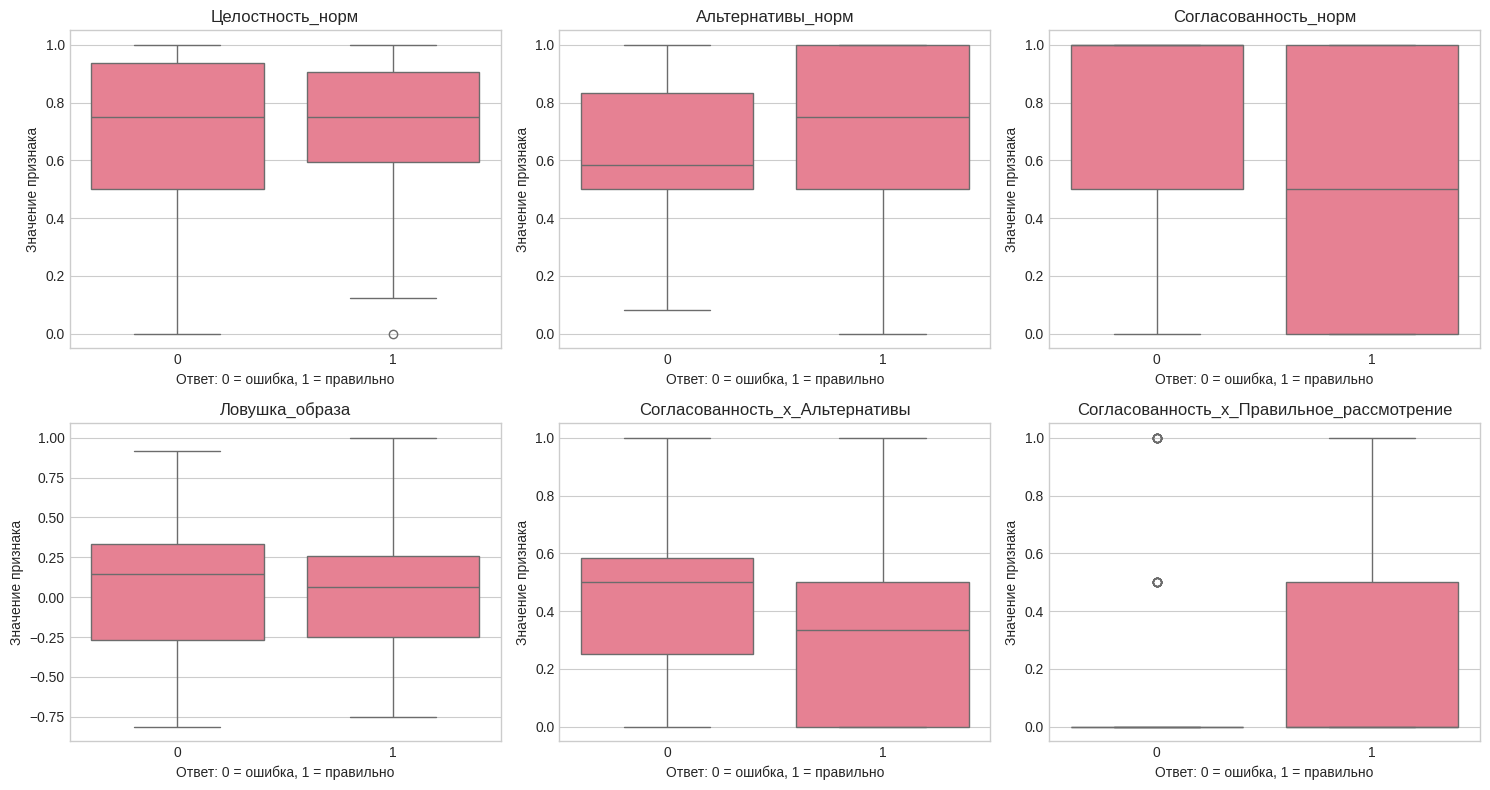

In [191]:
# ------------------------------------------------------------
# Распределения новых признаков по правильности ответа
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for i, col in enumerate(feature_check):
    sns.boxplot(
        data=df,
        x='ответ',
        y=col,
        ax=axes[i]
    )
    axes[i].set_title(col)
    axes[i].set_xlabel('Ответ: 0 = ошибка, 1 = правильно')
    axes[i].set_ylabel('Значение признака')

plt.tight_layout()
plt.show()

## Подготовка признаков к моделированию

После EDA и feature engineering были выделены несколько психологически осмысленных групп признаков.  
Задача моделирования состоит не только в максимизации метрик, но и в сравнении разных объяснительных гипотез:

1. базовая гипотеза: правильность ответа зависит от содержательной согласованности задачи;
2. гипотеза рассуждения: важен не только тип задачи, но и правильное рассмотрение вариантов;
3. гипотеза альтернатив: работа с альтернативами может повышать вероятность правильного ответа;
4. расширенная гипотеза: эффект альтернатив и правильного рассмотрения может зависеть от силы содержательной ловушки.

Так как каждый участник решал несколько задач, ответы внутри одного участника не являются полностью независимыми. Поэтому при оценке моделей используется группировка по `ID`: ответы одного участника не должны одновременно попадать и в train, и в test.

In [192]:
# ============================================================
# ПОДГОТОВКА ПРИЗНАКОВ ДЛЯ МОДЕЛЕЙ
# ============================================================

# Важно:
# мы не используем признаки, напрямую рассчитанные из целевой переменной,
# например "Количество_правильных_ответов".
# Это могло бы привести к утечке данных, потому что такой признак уже знает,
# насколько успешно участник отвечал в целом.

target = 'ответ'
group_col = 'ID'

# Проверяем, что целевая переменная и ID есть в данных
required_model_cols = [target, group_col]
missing_model_cols = [col for col in required_model_cols if col not in df.columns]

if missing_model_cols:
    raise ValueError(f"Не найдены обязательные колонки: {missing_model_cols}")
else:
    print("Целевая переменная и группировка по ID найдены.")

Целевая переменная и группировка по ID найдены.


In [193]:
# ------------------------------------------------------------
# Центрированное взаимодействие согласованности и альтернатив
# ------------------------------------------------------------
# Обычное произведение согласованности и альтернативности может быть сложно
# интерпретировать, потому что оно частично повторяет главный эффект согласованности.
#
# Поэтому для модели добавляем центрированное взаимодействие:
# сначала вычитаем среднее, затем перемножаем.
#
# Такой признак лучше отражает именно совместный эффект:
# меняется ли роль альтернатив в зависимости от уровня согласованности задачи.

df['Согласованность_центр'] = (
    df['Согласованность_норм'] - df['Согласованность_норм'].mean()
)

df['Альтернативы_центр'] = (
    df['Альтернативы_норм'] - df['Альтернативы_норм'].mean()
)

df['Согласованность_x_Альтернативы_центр'] = (
    df['Согласованность_центр'] * df['Альтернативы_центр']
)

In [194]:
# ============================================================
# НАБОРЫ ПРИЗНАКОВ
# ============================================================

# ------------------------------------------------------------
# 1. Базовая модель
# ------------------------------------------------------------
# Проверяет, насколько правильность ответа объясняется только
# содержательной согласованностью задачи.

features_base = [
    'Согласованность_норм'
]


# ------------------------------------------------------------
# 2. Модель рассуждения
# ------------------------------------------------------------
# Добавляет признак правильного рассмотрения вариантов.
# Это один из самых психологически важных признаков:
# участник мог назвать альтернативы, но принципиально важно,
# понял ли он отношение общего и частного.

features_reasoning = [
    'Согласованность_норм',
    'Рассматривали_варианты_правильно'
]


# ------------------------------------------------------------
# 3. Модель альтернатив
# ------------------------------------------------------------
# Добавляет общий индекс альтернативности.
# В EDA он показал слабую положительную связь с правильностью,
# поэтому его имеет смысл проверить в модели, но не делать главным выводом заранее.

features_alternatives = [
    'Согласованность_норм',
    'Рассматривали_варианты_правильно',
    'Альтернативы_норм'
]


# ------------------------------------------------------------
# 4. Расширенная интерпретируемая модель
# ------------------------------------------------------------
# Добавляет взаимодействия.
# Эта модель проверяет, зависит ли эффект правильного рассмотрения вариантов
# и альтернативности от силы содержательной ловушки.

features_interactions = [
    'Согласованность_норм',
    'Рассматривали_варианты_правильно',
    'Альтернативы_норм',
    'Согласованность_x_Правильное_рассмотрение',
    'Согласованность_x_Альтернативы_центр'
]


# ------------------------------------------------------------
# 5. Теоретическая модель с ловушкой образа
# ------------------------------------------------------------
# Индекс "Ловушка_образа" теоретически осмысленный,
# но в EDA он не показал самостоятельной связи с правильностью.
# Поэтому эту модель можно проверить как дополнительную,
# но не делать её основной.

features_trap = [
    'Согласованность_норм',
    'Рассматривали_варианты_правильно',
    'Альтернативы_норм',
    'Ловушка_образа'
]


feature_sets = {
    'M1_base': features_base,
    'M2_reasoning': features_reasoning,
    'M3_alternatives': features_alternatives,
    'M4_interactions': features_interactions,
    'M5_trap_theoretical': features_trap
}

for name, features in feature_sets.items():
    print(name, ":", features)

M1_base : ['Согласованность_норм']
M2_reasoning : ['Согласованность_норм', 'Рассматривали_варианты_правильно']
M3_alternatives : ['Согласованность_норм', 'Рассматривали_варианты_правильно', 'Альтернативы_норм']
M4_interactions : ['Согласованность_норм', 'Рассматривали_варианты_правильно', 'Альтернативы_норм', 'Согласованность_x_Правильное_рассмотрение', 'Согласованность_x_Альтернативы_центр']
M5_trap_theoretical : ['Согласованность_норм', 'Рассматривали_варианты_правильно', 'Альтернативы_норм', 'Ловушка_образа']


In [196]:
# ------------------------------------------------------------
# Проверка пропусков в выбранных признаках
# ------------------------------------------------------------

all_model_features = sorted(set(sum(feature_sets.values(), [])))

missing_in_features = df[all_model_features].isna().sum()
missing_in_features = missing_in_features[missing_in_features > 0]

if len(missing_in_features) > 0:
    print("Есть пропуски в признаках:")
    display(missing_in_features)
else:
    print("Пропусков в выбранных признаках нет.")

print("\nИтоговый список всех признаков, которые могут использоваться в моделях:")
for col in all_model_features:
    print("-", col)

Пропусков в выбранных признаках нет.

Итоговый список всех признаков, которые могут использоваться в моделях:
- Альтернативы_норм
- Ловушка_образа
- Рассматривали_варианты_правильно
- Согласованность_x_Альтернативы_центр
- Согласованность_x_Правильное_рассмотрение
- Согласованность_норм


In [198]:
# ============================================================
# БАЗОВЫЕ ПЕРЕМЕННЫЕ
# ============================================================

target = 'ответ'
group_col = 'ID'

X_all = df.copy()
y = df[target].astype(int)
groups = df[group_col]

print("Размер данных:", df.shape)
print("Количество участников:", df[group_col].nunique())
print("Распределение целевой переменной:")
print(y.value_counts(normalize=True).round(3))

Размер данных: (200, 51)
Количество участников: 40
Распределение целевой переменной:
ответ
1    0.535
0    0.465
Name: proportion, dtype: float64


### Универсальная функция оценки моделей

Для корректного сравнения моделей была написана единая функция оценки качества. Она принимает модель, набор признаков и название модели, затем обучает и тестирует модель с помощью GroupKFold.

Использование GroupKFold связано со структурой данных: каждый участник решал несколько задач, поэтому строки не являются полностью независимыми. Если ответы одного участника попадут одновременно в обучающую и тестовую выборку, качество модели может быть завышено. GroupKFold разделяет данные по ID участника и позволяет оценить, насколько модель обобщается на новых участников.

Для каждой модели рассчитывались несколько метрик: ROC-AUC, Accuracy, F1, Precision и Recall. Основной метрикой сравнения использовался ROC-AUC, так как задача является бинарной, а эта метрика показывает, насколько хорошо модель различает правильные и ошибочные ответы независимо от выбранного порога классификации. Остальные метрики использовались как дополнительные: Accuracy показывает общую долю верных классификаций, F1 учитывает баланс Precision и Recall, Precision показывает точность предсказаний правильного ответа, а Recall — насколько полно модель находит правильные ответы.

Функция возвращает средние значения метрик и стандартные отклонения по фолдам. Это позволяет сравнивать модели не по одному случайному разбиению, а по более устойчивой кросс-валидационной оценке.


In [199]:
# ============================================================
# УНИВЕРСАЛЬНАЯ ФУНКЦИЯ ДЛЯ ОЦЕНКИ МОДЕЛЕЙ
# ============================================================

def fit_model(model, features, model_name, df, target='ответ', group_col='ID', n_splits=5):
    """
    Обучает и оценивает модель с помощью GroupKFold.

    Почему GroupKFold:
    один участник решал несколько задач, поэтому его ответы зависимы.
    GroupKFold следит за тем, чтобы ответы одного и того же участника
    не попадали одновременно в train и test.

    Параметры:
    model — модель sklearn или pipeline;
    features — список признаков;
    model_name — название модели для таблицы результатов;
    df — датафрейм;
    target — целевая переменная;
    group_col — колонка с ID участника;
    n_splits — число фолдов.

    Возвращает:
    словарь со средними метриками и стандартными отклонениями.
    """

    X = df[features].copy()
    y = df[target].astype(int)
    groups = df[group_col]

    cv = GroupKFold(n_splits=n_splits)

    auc_scores = []
    acc_scores = []
    f1_scores = []
    precision_scores = []
    recall_scores = []

    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups), start=1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        current_model = clone(model)
        current_model.fit(X_train, y_train)

        y_pred = current_model.predict(X_test)

        # Для AUC нужны вероятности класса 1
        if hasattr(current_model, "predict_proba"):
            y_proba = current_model.predict_proba(X_test)[:, 1]
        else:
            y_proba = y_pred

        # AUC считаем только если в тестовом фолде есть оба класса
        if len(np.unique(y_test)) == 2:
            auc = roc_auc_score(y_test, y_proba)
        else:
            auc = np.nan

        auc_scores.append(auc)
        acc_scores.append(accuracy_score(y_test, y_pred))
        f1_scores.append(f1_score(y_test, y_pred, zero_division=0))
        precision_scores.append(precision_score(y_test, y_pred, zero_division=0))
        recall_scores.append(recall_score(y_test, y_pred, zero_division=0))

    result = {
        'Модель': model_name,
        'N_features': len(features),
        'Признаки': ', '.join(features),

        'ROC_AUC_mean': np.nanmean(auc_scores),
        'ROC_AUC_std': np.nanstd(auc_scores),

        'Accuracy_mean': np.mean(acc_scores),
        'Accuracy_std': np.std(acc_scores),

        'F1_mean': np.mean(f1_scores),
        'F1_std': np.std(f1_scores),

        'Precision_mean': np.mean(precision_scores),
        'Precision_std': np.std(precision_scores),

        'Recall_mean': np.mean(recall_scores),
        'Recall_std': np.std(recall_scores)
    }

    return result

In [200]:
# ============================================================
# МОДЕЛИ ДЛЯ СРАВНЕНИЯ
# ============================================================

# DummyClassifier — наивная baseline-модель.
# Она нужна, чтобы понять, лучше ли наши модели простого угадывания
# наиболее частого класса.

dummy_model = DummyClassifier(strategy='most_frequent')


# Логистическая регрессия — основная интерпретируемая модель.
# StandardScaler используется, чтобы признаки были сопоставимы по масштабу.
# Это особенно важно для коэффициентов логистической регрессии.

logreg_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [201]:
# ============================================================
# СРАВНЕНИЕ НАБОРОВ ПРИЗНАКОВ НА ЛОГИСТИЧЕСКОЙ РЕГРЕССИИ
# ============================================================

results = []

# Baseline без психологических признаков:
# просто предсказывает самый частый класс.
results.append(
    fit_model(
        model=dummy_model,
        features=features_base,
        model_name='M0_dummy_baseline',
        df=df,
        target=target,
        group_col=group_col
    )
)

# Логистическая регрессия на разных наборах признаков
for name, features in feature_sets.items():
    result = fit_model(
        model=logreg_model,
        features=features,
        model_name=f'LogReg_{name}',
        df=df,
        target=target,
        group_col=group_col
    )
    results.append(result)

results_df = pd.DataFrame(results)

# Округляем метрики для удобства чтения
metric_cols = [
    'ROC_AUC_mean', 'ROC_AUC_std',
    'Accuracy_mean', 'Accuracy_std',
    'F1_mean', 'F1_std',
    'Precision_mean', 'Precision_std',
    'Recall_mean', 'Recall_std'
]

results_df[metric_cols] = results_df[metric_cols].round(3)

results_df.sort_values('ROC_AUC_mean', ascending=False)

,Модель,N_features,Признаки,ROC_AUC_mean,ROC_AUC_std,Accuracy_mean,Accuracy_std,F1_mean,F1_std,Precision_mean,Precision_std,Recall_mean,Recall_std
5,LogReg_M5_trap_theoretical,4,"Согласованность_норм, Рассматривали_варианты_п...",0.820,0.047,0.760,0.034,0.782,0.036,0.757,0.052,0.813,0.047
3,LogReg_M3_alternatives,3,"Согласованность_норм, Рассматривали_варианты_п...",0.818,0.050,0.745,0.037,0.764,0.044,0.749,0.056,0.783,0.051
2,LogReg_M2_reasoning,2,"Согласованность_норм, Рассматривали_варианты_п...",0.806,0.045,0.765,0.051,0.774,0.056,0.796,0.102,0.765,0.073
4,LogReg_M4_interactions,5,"Согласованность_норм, Рассматривали_варианты_п...",0.793,0.083,0.740,0.044,0.761,0.047,0.744,0.064,0.783,0.051
1,LogReg_M1_base,1,Согласованность_норм,0.672,0.047,0.625,0.057,0.670,0.047,0.633,0.049,0.713,0.060
0,M0_dummy_baseline,1,Согласованность_норм,0.500,0.000,0.535,0.046,0.696,0.039,0.535,0.046,1.000,0.000


In [242]:
# ============================================================
# ПРОВЕРКА ГИПЕРПАРАМЕТРА C ДЛЯ ЛОГИСТИЧЕСКОЙ РЕГРЕССИИ
# ============================================================
# Для логистической регрессии основной гиперпараметр — C.
# Он регулирует силу L2-регуляризации:
# меньше C = сильнее регуляризация,
# больше C = слабее регуляризация.
#
# Здесь проверяем несколько значений C для лучшего набора признаков.
# Это не основной содержательный анализ, а проверка устойчивости качества модели.

logreg_c_grid = [0.1, 0.3, 1.0, 3.0, 10.0]

logreg_tuning_results = []

for C in logreg_c_grid:
    tuned_logreg_model = Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            C=C,
            penalty='l2',
            solver='liblinear',
            max_iter=1000,
            random_state=42
        ))
    ])

    result = fit_model(
        model=tuned_logreg_model,
        features=features_trap,   # здесь используй лучший/итоговый набор признаков
        model_name=f'LogReg_C={C}',
        df=df,
        target=target,
        group_col=group_col
    )

    result['C'] = C
    logreg_tuning_results.append(result)

logreg_tuning_df = pd.DataFrame(logreg_tuning_results)

logreg_tuning_df[metric_cols] = logreg_tuning_df[metric_cols].round(3)

print("Проверка гиперпараметра C для логистической регрессии:")
display(
    logreg_tuning_df
    .sort_values('ROC_AUC_mean', ascending=False)
    [
        [
            'Модель',
            'C',
            'ROC_AUC_mean',
            'ROC_AUC_std',
            'Accuracy_mean',
            'F1_mean',
            'Precision_mean',
            'Recall_mean'
        ]
    ]
)

Проверка гиперпараметра C для логистической регрессии:


,Модель,C,ROC_AUC_mean,ROC_AUC_std,Accuracy_mean,F1_mean,Precision_mean,Recall_mean
1,LogReg_C=0.3,0.3,0.820,0.048,0.750,0.770,0.752,0.793
4,LogReg_C=10.0,10.0,0.820,0.045,0.755,0.778,0.750,0.813
3,LogReg_C=3.0,3.0,0.820,0.045,0.755,0.778,0.750,0.813
2,LogReg_C=1.0,1.0,0.819,0.047,0.760,0.782,0.757,0.813
0,LogReg_C=0.1,0.1,0.818,0.047,0.750,0.770,0.752,0.793


In [202]:
def fit_glm_cluster(df, features, model_name, target='ответ', group_col='ID'):
    """
    Логистическая GLM-модель с кластер-робастными стандартными ошибками по ID.

    Зачем:
    sklearn LogisticRegression использовалась для оценки предсказательного качества.
    GLM через statsmodels используется для интерпретации:
    коэффициенты, p-value, odds ratio.

    Cluster-robust SE нужны, потому что один участник дал несколько ответов.
    """

    formula = target + ' ~ ' + ' + '.join([f'Q("{f}")' for f in features])

    model = smf.glm(
        formula=formula,
        data=df,
        family=sm.families.Binomial()
    )

    result = model.fit(
        cov_type='cluster',
        cov_kwds={'groups': df[group_col]}
    )

    coef_table = pd.DataFrame({
        'Модель': model_name,
        'Признак': result.params.index,
        'coef': result.params.values,
        'OR': np.exp(result.params.values),
        'p_value': result.pvalues.values,
        'CI_low_OR': np.exp(result.conf_int()[0].values),
        'CI_high_OR': np.exp(result.conf_int()[1].values)
    })

    return result, coef_table

In [203]:
glm_m2, glm_m2_table = fit_glm_cluster(
    df=df,
    features=features_reasoning,
    model_name='GLM_M2_reasoning',
    target=target,
    group_col=group_col
)

glm_m5, glm_m5_table = fit_glm_cluster(
    df=df,
    features=features_trap,
    model_name='GLM_M5_trap_theoretical',
    target=target,
    group_col=group_col
)

glm_results_table = pd.concat([glm_m2_table, glm_m5_table], ignore_index=True)

glm_results_table[
    ['Модель', 'Признак', 'coef', 'OR', 'p_value', 'CI_low_OR', 'CI_high_OR']
].round(3)

,Модель,Признак,coef,OR,p_value,CI_low_OR,CI_high_OR
0,GLM_M2_reasoning,Intercept,0.787,2.197,0.007,1.243,3.886
1,GLM_M2_reasoning,"Q(""Согласованность_норм"")",-2.367,0.094,0.000,0.040,0.221
2,GLM_M2_reasoning,"Q(""Рассматривали_варианты_правильно"")",2.157,8.646,0.000,3.149,23.736
3,GLM_M5_trap_theoretical,Intercept,-0.769,0.464,0.347,0.093,2.300
4,GLM_M5_trap_theoretical,"Q(""Согласованность_норм"")",-2.403,0.090,0.000,0.037,0.224
5,GLM_M5_trap_theoretical,"Q(""Рассматривали_варианты_правильно"")",2.201,9.032,0.000,3.315,24.609
6,GLM_M5_trap_theoretical,"Q(""Альтернативы_норм"")",2.291,9.887,0.057,0.931,104.963
7,GLM_M5_trap_theoretical,"Q(""Ловушка_образа"")",0.782,2.185,0.329,0.455,10.484


In [205]:
# ============================================================
# ПРИЗНАКИ ДЛЯ CATBOOST
# ============================================================

# Используем компактный набор признаков:
# он включает ключевые предикторы из логистической модели
# и дополнительные психологически осмысленные индексы.

catboost_features = [
    'Согласованность_норм',
    'Рассматривали_варианты_правильно',
    'Альтернативы_норм',
    'Ловушка_образа'
]

target = 'ответ'
group_col = 'ID'

# Проверка наличия признаков
missing_cols = [col for col in catboost_features + [target, group_col] if col not in df.columns]

if missing_cols:
    raise ValueError(f"Не найдены колонки: {missing_cols}")
else:
    print("Все признаки для CatBoost найдены.")

Все признаки для CatBoost найдены.


In [206]:
# ============================================================
# ФУНКЦИЯ ОЦЕНКИ CATBOOST ЧЕРЕЗ GROUPKFOLD
# ============================================================

def fit_catboost_model(
    df,
    features,
    model_name,
    params=None,
    target='ответ',
    group_col='ID',
    n_splits=5
):
    """
    Оценивает CatBoostClassifier через GroupKFold.

    GroupKFold нужен, потому что каждый участник решал несколько задач.
    Ответы одного участника не должны одновременно попадать в train и test.

    CatBoost используется как более гибкая модель:
    он может учитывать нелинейности и взаимодействия признаков.
    """

    if params is None:
        params = {}

    X = df[features].copy()
    y = df[target].astype(int)
    groups = df[group_col]

    cv = GroupKFold(n_splits=n_splits)

    auc_scores = []
    acc_scores = []
    f1_scores = []
    precision_scores = []
    recall_scores = []

    feature_importances = []

    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups), start=1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        model = CatBoostClassifier(
            loss_function='Logloss',
            eval_metric='AUC',
            random_seed=42,
            verbose=False,
            **params
        )

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]

        if len(np.unique(y_test)) == 2:
            auc = roc_auc_score(y_test, y_proba)
        else:
            auc = np.nan

        auc_scores.append(auc)
        acc_scores.append(accuracy_score(y_test, y_pred))
        f1_scores.append(f1_score(y_test, y_pred, zero_division=0))
        precision_scores.append(precision_score(y_test, y_pred, zero_division=0))
        recall_scores.append(recall_score(y_test, y_pred, zero_division=0))

        feature_importances.append(model.get_feature_importance())

    result = {
        'Модель': model_name,
        'N_features': len(features),
        'Признаки': ', '.join(features),

        'ROC_AUC_mean': np.nanmean(auc_scores),
        'ROC_AUC_std': np.nanstd(auc_scores),

        'Accuracy_mean': np.mean(acc_scores),
        'Accuracy_std': np.std(acc_scores),

        'F1_mean': np.mean(f1_scores),
        'F1_std': np.std(f1_scores),

        'Precision_mean': np.mean(precision_scores),
        'Precision_std': np.std(precision_scores),

        'Recall_mean': np.mean(recall_scores),
        'Recall_std': np.std(recall_scores)
    }

    importance_df = pd.DataFrame({
        'Признак': features,
        'Importance_mean': np.mean(feature_importances, axis=0),
        'Importance_std': np.std(feature_importances, axis=0)
    }).sort_values('Importance_mean', ascending=False)

    return result, importance_df

In [207]:
# ============================================================
# БАЗОВЫЙ CATBOOST
# ============================================================

catboost_base_params = {
    'iterations': 200,
    'depth': 2,
    'learning_rate': 0.05,
    'l2_leaf_reg': 5
}

catboost_result, catboost_importance = fit_catboost_model(
    df=df,
    features=catboost_features,
    model_name='CatBoost_base',
    params=catboost_base_params,
    target=target,
    group_col=group_col
)

pd.DataFrame([catboost_result]).round(3)

,Модель,N_features,Признаки,ROC_AUC_mean,ROC_AUC_std,Accuracy_mean,Accuracy_std,F1_mean,F1_std,Precision_mean,Precision_std,Recall_mean,Recall_std
0,CatBoost_base,4,"Согласованность_норм, Рассматривали_варианты_п...",0.76,0.067,0.72,0.053,0.741,0.068,0.726,0.086,0.762,0.08


In [208]:
# ============================================================
# ВАЖНОСТЬ ПРИЗНАКОВ CATBOOST
# ============================================================

catboost_importance.round(3)

,Признак,Importance_mean,Importance_std
3,Ловушка_образа,32.835,3.721
1,Рассматривали_варианты_правильно,30.782,2.296
0,Согласованность_норм,26.876,3.376
2,Альтернативы_норм,9.507,1.633


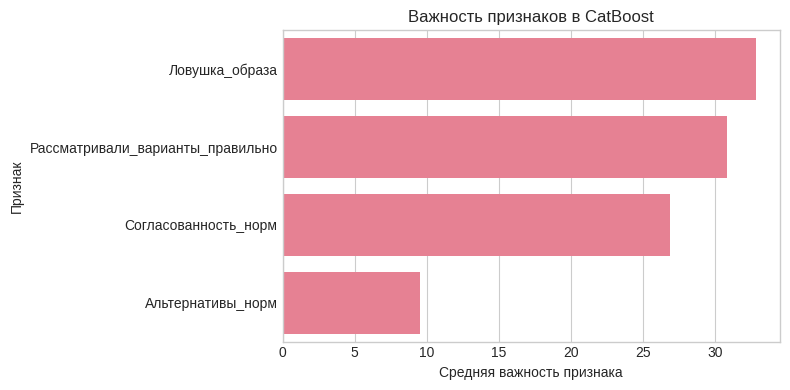

In [209]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=catboost_importance,
    x='Importance_mean',
    y='Признак'
)

plt.title('Важность признаков в CatBoost')
plt.xlabel('Средняя важность признака')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

In [237]:
# ============================================================
# ПОДБОР ГИПЕРПАРАМЕТРОВ CATBOOST
# ============================================================
# CatBoost используется как более гибкая модель, способная учитывать
# нелинейные зависимости и взаимодействия между признаками.
#
# Так как выборка небольшая, число деревьев специально ограничивается.
# В CatBoost параметр iterations означает количество деревьев в ансамбле,
# а не "итерации сходимости" в смысле логистической регрессии.

param_grid = [
    {'iterations': 20, 'depth': 2, 'learning_rate': 0.05, 'l2_leaf_reg': 3},
    {'iterations': 30, 'depth': 2, 'learning_rate': 0.05, 'l2_leaf_reg': 3},
    {'iterations': 50, 'depth': 2, 'learning_rate': 0.05, 'l2_leaf_reg': 3},

    {'iterations': 20, 'depth': 3, 'learning_rate': 0.03, 'l2_leaf_reg': 10},
    {'iterations': 30, 'depth': 3, 'learning_rate': 0.03, 'l2_leaf_reg': 10},
    {'iterations': 50, 'depth': 3, 'learning_rate': 0.03, 'l2_leaf_reg': 10}
]

catboost_tuning_results = []
catboost_importances = {}

for i, params in enumerate(param_grid, start=1):
    result, importance = fit_catboost_model(
        df=df,
        features=catboost_features,
        model_name=f'CatBoost_tuned_{i}',
        params=params,
        target=target,
        group_col=group_col
    )

    result['params'] = params
    result['iterations'] = params['iterations']
    result['depth'] = params['depth']
    result['learning_rate'] = params['learning_rate']
    result['l2_leaf_reg'] = params['l2_leaf_reg']

    catboost_tuning_results.append(result)
    catboost_importances[result['Модель']] = importance

catboost_tuning_df = pd.DataFrame(catboost_tuning_results)

metric_cols = [
    'ROC_AUC_mean', 'ROC_AUC_std',
    'Accuracy_mean', 'Accuracy_std',
    'F1_mean', 'F1_std',
    'Precision_mean', 'Precision_std',
    'Recall_mean', 'Recall_std'
]

catboost_tuning_df[metric_cols] = catboost_tuning_df[metric_cols].round(3)

catboost_tuning_df_sorted = (
    catboost_tuning_df
    .sort_values('ROC_AUC_mean', ascending=False)
    .reset_index(drop=True)
)

print("Результаты подбора гиперпараметров CatBoost:")
display(
    catboost_tuning_df_sorted[
        [
            'Модель',
            'iterations',
            'depth',
            'learning_rate',
            'l2_leaf_reg',
            'ROC_AUC_mean',
            'ROC_AUC_std',
            'Accuracy_mean',
            'F1_mean',
            'Precision_mean',
            'Recall_mean'
        ]
    ]
)

Результаты подбора гиперпараметров CatBoost:


,Модель,iterations,depth,learning_rate,l2_leaf_reg,ROC_AUC_mean,ROC_AUC_std,Accuracy_mean,F1_mean,Precision_mean,Recall_mean
0,CatBoost_tuned_4,20,3,0.03,10,0.811,0.047,0.755,0.763,0.792,0.747
1,CatBoost_tuned_6,50,3,0.03,10,0.809,0.045,0.760,0.768,0.793,0.755
2,CatBoost_tuned_5,30,3,0.03,10,0.805,0.045,0.765,0.774,0.796,0.765
3,CatBoost_tuned_2,30,2,0.05,3,0.804,0.052,0.765,0.774,0.796,0.765
4,CatBoost_tuned_3,50,2,0.05,3,0.804,0.050,0.760,0.769,0.795,0.757
5,CatBoost_tuned_1,20,2,0.05,3,0.802,0.055,0.760,0.769,0.795,0.757


In [238]:
# ============================================================
# ВЫБОР ИТОГОВОЙ CATBOOST-МОДЕЛИ ПО ПРИНЦИПУ ПАРСИМОНИИ
# ============================================================
# Если несколько моделей показывают близкое качество,
# выбираем более простую модель: меньше деревьев и меньшую глубину.
#
# Здесь считаем модели практически сопоставимыми,
# если их ROC-AUC отличается от лучшего не более чем на 0.01.

best_auc = catboost_tuning_df['ROC_AUC_mean'].max()
auc_tolerance = 0.01

catboost_candidates = catboost_tuning_df[
    catboost_tuning_df['ROC_AUC_mean'] >= best_auc - auc_tolerance
].copy()

final_catboost_row = (
    catboost_candidates
    .sort_values(
        by=['iterations', 'depth', 'ROC_AUC_mean'],
        ascending=[True, True, False]
    )
    .iloc[0]
)

final_catboost_name = final_catboost_row['Модель']
final_catboost_params = final_catboost_row['params']
final_catboost_importance = catboost_importances[final_catboost_name]

print("Формально лучший ROC-AUC:", round(best_auc, 3))
print("Итоговая CatBoost-модель по принципу парсимонии:", final_catboost_name)
print("Параметры итоговой модели:", final_catboost_params)

display(
    pd.DataFrame([final_catboost_row])[
        [
            'Модель',
            'iterations',
            'depth',
            'learning_rate',
            'l2_leaf_reg',
            'ROC_AUC_mean',
            'ROC_AUC_std',
            'Accuracy_mean',
            'F1_mean',
            'Precision_mean',
            'Recall_mean'
        ]
    ]
)

Формально лучший ROC-AUC: 0.811
Итоговая CatBoost-модель по принципу парсимонии: CatBoost_tuned_1
Параметры итоговой модели: {'iterations': 20, 'depth': 2, 'learning_rate': 0.05, 'l2_leaf_reg': 3}


,Модель,iterations,depth,learning_rate,l2_leaf_reg,ROC_AUC_mean,ROC_AUC_std,Accuracy_mean,F1_mean,Precision_mean,Recall_mean
0,CatBoost_tuned_1,20,2,0.05,3,0.802,0.055,0.76,0.769,0.795,0.757


Итоговая CatBoost-модель: CatBoost_tuned_1


,Признак,Importance_mean,Importance_std
1,Рассматривали_варианты_правильно,67.279,2.856
0,Согласованность_норм,28.916,2.227
3,Ловушка_образа,2.057,0.916
2,Альтернативы_норм,1.748,0.882


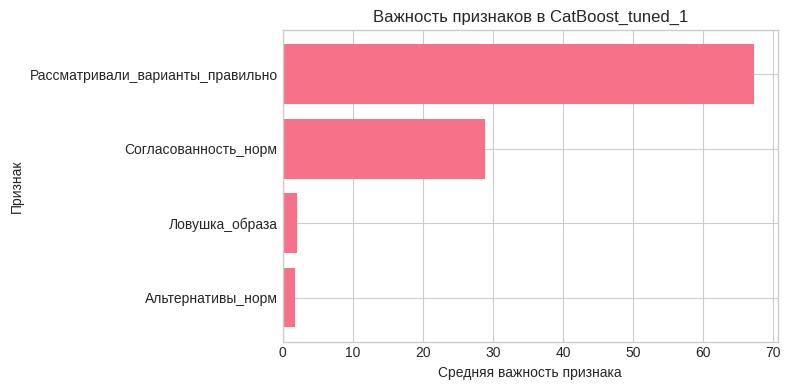

In [239]:
# ============================================================
# ВАЖНОСТЬ ПРИЗНАКОВ ИТОГОВОЙ CATBOOST-МОДЕЛИ
# ============================================================

print("Итоговая CatBoost-модель:", final_catboost_name)

display(final_catboost_importance.round(3))

plt.figure(figsize=(8, 4))

plt.barh(
    final_catboost_importance['Признак'],
    final_catboost_importance['Importance_mean']
)

plt.xlabel('Средняя важность признака')
plt.ylabel('Признак')
plt.title(f'Важность признаков в {final_catboost_name}')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [240]:
# ============================================================
# СРАВНЕНИЕ МОДЕЛЕЙ
# ============================================================

final_catboost = (
    pd.DataFrame([final_catboost_row])
    .drop(columns=['params'], errors='ignore')
)

final_comparison_df = pd.concat([
    results_df,
    final_catboost
], ignore_index=True)

final_comparison_df[metric_cols] = final_comparison_df[metric_cols].round(3)

final_comparison_df.sort_values('ROC_AUC_mean', ascending=False)

,Модель,N_features,Признаки,ROC_AUC_mean,ROC_AUC_std,Accuracy_mean,Accuracy_std,F1_mean,F1_std,Precision_mean,Precision_std,Recall_mean,Recall_std,iterations,depth,learning_rate,l2_leaf_reg
5,LogReg_M5_trap_theoretical,4,"Согласованность_норм, Рассматривали_варианты_п...",0.820,0.047,0.760,0.034,0.782,0.036,0.757,0.052,0.813,0.047,NaN,NaN,NaN,NaN
3,LogReg_M3_alternatives,3,"Согласованность_норм, Рассматривали_варианты_п...",0.818,0.050,0.745,0.037,0.764,0.044,0.749,0.056,0.783,0.051,NaN,NaN,NaN,NaN
2,LogReg_M2_reasoning,2,"Согласованность_норм, Рассматривали_варианты_п...",0.806,0.045,0.765,0.051,0.774,0.056,0.796,0.102,0.765,0.073,NaN,NaN,NaN,NaN
6,CatBoost_tuned_1,4,"Согласованность_норм, Рассматривали_варианты_п...",0.802,0.055,0.760,0.044,0.769,0.047,0.795,0.101,0.757,0.062,20.0,2.0,0.05,3.0
4,LogReg_M4_interactions,5,"Согласованность_норм, Рассматривали_варианты_п...",0.793,0.083,0.740,0.044,0.761,0.047,0.744,0.064,0.783,0.051,NaN,NaN,NaN,NaN
1,LogReg_M1_base,1,Согласованность_норм,0.672,0.047,0.625,0.057,0.670,0.047,0.633,0.049,0.713,0.060,NaN,NaN,NaN,NaN
0,M0_dummy_baseline,1,Согласованность_норм,0.500,0.000,0.535,0.046,0.696,0.039,0.535,0.046,1.000,0.000,NaN,NaN,NaN,NaN


In [241]:
# ============================================================
# ОТДЕЛЬНЫЙ БЛОК: ДОБАВЛЕНИЕ REI-ПРИЗНАКОВ
# ============================================================
# В этом блоке проверяем, добавляют ли индивидуальные показатели
# интуитивного и рационального стиля мышления дополнительную
# предсказательную силу.
#
# Важно:
# REI-признаки относятся к уровню участника, а не к уровню отдельной задачи.
# Они одинаковы для всех 5 ответов одного участника.
# Поэтому оценка моделей снова проводится через GroupKFold по ID,
# чтобы ответы одного участника не попадали одновременно в train и test.


# ------------------------------------------------------------
# 1. Задаём REI-признаки
# ------------------------------------------------------------

rei_raw_features = [
    'Использование_интуиции',
    'Интуитивная_способность',
    'Использование_рациональности',
    'Способность_к_рациональным_решениям'
]

# Проверяем, что все REI-признаки есть в данных
missing_rei_cols = [col for col in rei_raw_features if col not in df.columns]

if missing_rei_cols:
    raise ValueError(f"Не найдены REI-признаки: {missing_rei_cols}")
else:
    print("Все REI-признаки найдены.")


# ------------------------------------------------------------
# 2. Стандартизация REI-признаков для интерпретации
# ------------------------------------------------------------
# Для логистической регрессии sklearn признаки и так масштабируются
# внутри Pipeline через StandardScaler.
#
# Но для GLM через statsmodels лучше отдельно создать z-версии,
# чтобы коэффициенты и OR интерпретировались как эффект увеличения
# признака на 1 стандартное отклонение.
#
# Это особенно удобно, потому что REI-признаки могут иметь другой масштаб,
# чем нормированные признаки задачи.

rei_z_features = []

for col in rei_raw_features:
    z_col = col + '_z'
    df[z_col] = (df[col] - df[col].mean()) / df[col].std()
    rei_z_features.append(z_col)

print("Созданы стандартизированные REI-признаки:")
for col in rei_z_features:
    print("-", col)


# ------------------------------------------------------------
# 3. Наборы признаков с REI
# ------------------------------------------------------------
# M6_REI_compact:
# REI добавляются к компактной и наиболее интерпретируемой модели M2.
#
# M7_REI_extended:
# REI добавляются к лучшей по ROC-AUC модели M5.
#
# Так мы проверяем два вопроса:
# 1) улучшают ли REI компактную модель;
# 2) дают ли REI прирост сверх лучшей расширенной модели.

features_rei_compact = [
    'Согласованность_норм',
    'Рассматривали_варианты_правильно'
] + rei_z_features

features_rei_extended = [
    'Согласованность_норм',
    'Рассматривали_варианты_правильно',
    'Альтернативы_норм',
    'Ловушка_образа'
] + rei_z_features

print("\nM6_REI_compact:")
print(features_rei_compact)

print("\nM7_REI_extended:")
print(features_rei_extended)


# ------------------------------------------------------------
# 4. Логистическая регрессия sklearn + GroupKFold
# ------------------------------------------------------------
# Здесь проверяем предсказательное качество:
# улучшается ли ROC-AUC, Accuracy, F1 после добавления REI.

rei_logreg_results = []

for model_name, features in {
    'LogReg_M6_REI_compact': features_rei_compact,
    'LogReg_M7_REI_extended': features_rei_extended
}.items():

    result = fit_model(
        model=logreg_model,
        features=features,
        model_name=model_name,
        df=df,
        target=target,
        group_col=group_col
    )

    rei_logreg_results.append(result)

rei_logreg_df = pd.DataFrame(rei_logreg_results)
rei_logreg_df[metric_cols] = rei_logreg_df[metric_cols].round(3)

print("\nРезультаты логистических моделей с REI:")
display(rei_logreg_df.sort_values('ROC_AUC_mean', ascending=False))


# ------------------------------------------------------------
# 5. GLM с кластер-робастными стандартными ошибками
# ------------------------------------------------------------
# Здесь проверяем интерпретацию:
# какие REI-признаки связаны с шансами правильного ответа
# при контроле согласованности задачи и правильного рассмотрения вариантов.

glm_m6_rei, glm_m6_rei_table = fit_glm_cluster(
    df=df,
    features=features_rei_compact,
    model_name='GLM_M6_REI_compact',
    target=target,
    group_col=group_col
)

glm_m7_rei, glm_m7_rei_table = fit_glm_cluster(
    df=df,
    features=features_rei_extended,
    model_name='GLM_M7_REI_extended',
    target=target,
    group_col=group_col
)

glm_rei_results_table = pd.concat(
    [glm_m6_rei_table, glm_m7_rei_table],
    ignore_index=True
)

glm_rei_display = glm_rei_results_table[
    ['Модель', 'Признак', 'coef', 'OR', 'p_value', 'CI_low_OR', 'CI_high_OR']
].copy()

glm_rei_display[['coef', 'OR', 'p_value', 'CI_low_OR', 'CI_high_OR']] = (
    glm_rei_display[['coef', 'OR', 'p_value', 'CI_low_OR', 'CI_high_OR']]
    .round(3)
)

print("\nGLM-интерпретация моделей с REI:")
display(glm_rei_display)


# ------------------------------------------------------------
# 6. CatBoost с REI
# ------------------------------------------------------------
# CatBoost проверяет, может ли более гибкая модель извлечь пользу
# из добавления индивидуальных REI-признаков.
#
# Используем те же аккуратные параметры, которые раньше оказались лучшими:
# простая модель с небольшой глубиной деревьев.
#
# На маленькой выборке не усложняем CatBoost чрезмерно.

catboost_rei_params = {
    'iterations': 20,
    'depth': 2,
    'learning_rate': 0.05,
    'l2_leaf_reg': 3
}

catboost_rei_result, catboost_rei_importance = fit_catboost_model(
    df=df,
    features=features_rei_extended,
    model_name='CatBoost_REI_extended',
    params=catboost_rei_params,
    target=target,
    group_col=group_col
)

catboost_rei_df = pd.DataFrame([catboost_rei_result])
catboost_rei_df[metric_cols] = catboost_rei_df[metric_cols].round(3)

print("\nCatBoost с REI:")
display(catboost_rei_df)

print("\nВажность признаков CatBoost с REI:")
display(catboost_rei_importance.round(3))


# ------------------------------------------------------------
# 7. Финальное сравнение: старые модели + REI-модели
# ------------------------------------------------------------
# Сравниваем:
# - лучшие логистические модели без REI;
# - CatBoost без REI;
# - логистические модели с REI;
# - CatBoost с REI.
#
# Главный вопрос:
# дают ли индивидуальные показатели интуиции и рациональности прирост
# сверх согласованности задачи и правильного рассмотрения вариантов?

final_comparison_with_rei = pd.concat([
    final_comparison_df,
    rei_logreg_df,
    catboost_rei_df
], ignore_index=True)

final_comparison_with_rei[metric_cols] = (
    final_comparison_with_rei[metric_cols].round(3)
)

print("\nФинальное сравнение моделей с учётом REI:")
display(
    final_comparison_with_rei
    .sort_values('ROC_AUC_mean', ascending=False)
    .reset_index(drop=True)
)

Все REI-признаки найдены.
Созданы стандартизированные REI-признаки:
- Использование_интуиции_z
- Интуитивная_способность_z
- Использование_рациональности_z
- Способность_к_рациональным_решениям_z

M6_REI_compact:
['Согласованность_норм', 'Рассматривали_варианты_правильно', 'Использование_интуиции_z', 'Интуитивная_способность_z', 'Использование_рациональности_z', 'Способность_к_рациональным_решениям_z']

M7_REI_extended:
['Согласованность_норм', 'Рассматривали_варианты_правильно', 'Альтернативы_норм', 'Ловушка_образа', 'Использование_интуиции_z', 'Интуитивная_способность_z', 'Использование_рациональности_z', 'Способность_к_рациональным_решениям_z']

Результаты логистических моделей с REI:


,Модель,N_features,Признаки,ROC_AUC_mean,ROC_AUC_std,Accuracy_mean,Accuracy_std,F1_mean,F1_std,Precision_mean,Precision_std,Recall_mean,Recall_std
0,LogReg_M6_REI_compact,6,"Согласованность_норм, Рассматривали_варианты_п...",0.821,0.049,0.755,0.062,0.776,0.061,0.767,0.112,0.804,0.094
1,LogReg_M7_REI_extended,8,"Согласованность_норм, Рассматривали_варианты_п...",0.811,0.021,0.740,0.020,0.761,0.031,0.754,0.082,0.788,0.102



GLM-интерпретация моделей с REI:


,Модель,Признак,coef,OR,p_value,CI_low_OR,CI_high_OR
0,GLM_M6_REI_compact,Intercept,0.796,2.216,0.012,1.195,4.107
1,GLM_M6_REI_compact,"Q(""Согласованность_норм"")",-2.492,0.083,0.000,0.034,0.202
2,GLM_M6_REI_compact,"Q(""Рассматривали_варианты_правильно"")",2.353,10.519,0.000,3.844,28.786
3,GLM_M6_REI_compact,"Q(""Использование_интуиции_z"")",0.741,2.099,0.093,0.883,4.989
4,GLM_M6_REI_compact,"Q(""Интуитивная_способность_z"")",-0.368,0.692,0.397,0.295,1.622
5,GLM_M6_REI_compact,"Q(""Использование_рациональности_z"")",0.271,1.312,0.178,0.884,1.946
6,GLM_M6_REI_compact,"Q(""Способность_к_рациональным_решениям_z"")",0.171,1.187,0.454,0.758,1.857
7,GLM_M7_REI_extended,Intercept,-1.075,0.341,0.251,0.054,2.142
8,GLM_M7_REI_extended,"Q(""Согласованность_норм"")",-2.535,0.079,0.000,0.031,0.202
9,GLM_M7_REI_extended,"Q(""Рассматривали_варианты_правильно"")",2.385,10.864,0.000,3.819,30.906



CatBoost с REI:


,Модель,N_features,Признаки,ROC_AUC_mean,ROC_AUC_std,Accuracy_mean,Accuracy_std,F1_mean,F1_std,Precision_mean,Precision_std,Recall_mean,Recall_std
0,CatBoost_REI_extended,8,"Согласованность_норм, Рассматривали_варианты_п...",0.788,0.029,0.765,0.051,0.774,0.056,0.796,0.102,0.765,0.073



Важность признаков CatBoost с REI:


,Признак,Importance_mean,Importance_std
1,Рассматривали_варианты_правильно,61.539,6.279
0,Согласованность_норм,26.241,2.391
4,Использование_интуиции_z,5.514,3.111
3,Ловушка_образа,2.514,1.366
6,Использование_рациональности_z,2.182,1.676
5,Интуитивная_способность_z,1.280,1.011
2,Альтернативы_норм,0.606,0.363
7,Способность_к_рациональным_решениям_z,0.123,0.133



Финальное сравнение моделей с учётом REI:


,Модель,N_features,Признаки,ROC_AUC_mean,ROC_AUC_std,Accuracy_mean,Accuracy_std,F1_mean,F1_std,Precision_mean,Precision_std,Recall_mean,Recall_std,iterations,depth,learning_rate,l2_leaf_reg
0,LogReg_M6_REI_compact,6,"Согласованность_норм, Рассматривали_варианты_п...",0.821,0.049,0.755,0.062,0.776,0.061,0.767,0.112,0.804,0.094,NaN,NaN,NaN,NaN
1,LogReg_M5_trap_theoretical,4,"Согласованность_норм, Рассматривали_варианты_п...",0.820,0.047,0.760,0.034,0.782,0.036,0.757,0.052,0.813,0.047,NaN,NaN,NaN,NaN
2,LogReg_M3_alternatives,3,"Согласованность_норм, Рассматривали_варианты_п...",0.818,0.050,0.745,0.037,0.764,0.044,0.749,0.056,0.783,0.051,NaN,NaN,NaN,NaN
3,LogReg_M7_REI_extended,8,"Согласованность_норм, Рассматривали_варианты_п...",0.811,0.021,0.740,0.020,0.761,0.031,0.754,0.082,0.788,0.102,NaN,NaN,NaN,NaN
4,LogReg_M2_reasoning,2,"Согласованность_норм, Рассматривали_варианты_п...",0.806,0.045,0.765,0.051,0.774,0.056,0.796,0.102,0.765,0.073,NaN,NaN,NaN,NaN
5,CatBoost_tuned_1,4,"Согласованность_норм, Рассматривали_варианты_п...",0.802,0.055,0.760,0.044,0.769,0.047,0.795,0.101,0.757,0.062,20.0,2.0,0.05,3.0
6,LogReg_M4_interactions,5,"Согласованность_норм, Рассматривали_варианты_п...",0.793,0.083,0.740,0.044,0.761,0.047,0.744,0.064,0.783,0.051,NaN,NaN,NaN,NaN
7,CatBoost_REI_extended,8,"Согласованность_норм, Рассматривали_варианты_п...",0.788,0.029,0.765,0.051,0.774,0.056,0.796,0.102,0.765,0.073,NaN,NaN,NaN,NaN
8,LogReg_M1_base,1,Согласованность_норм,0.672,0.047,0.625,0.057,0.670,0.047,0.633,0.049,0.713,0.060,NaN,NaN,NaN,NaN
9,M0_dummy_baseline,1,Согласованность_норм,0.500,0.000,0.535,0.046,0.696,0.039,0.535,0.046,1.000,0.000,NaN,NaN,NaN,NaN
